<a href="https://colab.research.google.com/github/erickcorrea3092/AZH_ACE_QSARMODEL/blob/main/5_AZH_selecci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# In this script, we will take a dataset based on a base molecule and then train a model; if possible, we can use Grid Search to find the best hyperparameters.

# En este script vamos a tomar un conjunto de datos basados en una molécula base y luego vamos a entrenar un modelo, si es posible podemos usar Grid Serach para buscar los mejores hiperparametros

# Antecedentes

## Imports

In [1]:
! pip install rdkit molplotly

In [2]:
import numpy as np
import pandas as pd
import seaborn as sn

import sklearn
from sklearn.model_selection import KFold, StratifiedShuffleSplit


from sklearn.svm import SVR
from sklearn.svm import NuSVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, StratifiedShuffleSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer
from sklearn.feature_selection import (SelectFromModel, SelectKBest,
                                       VarianceThreshold)

#---------------------- RDKit packages
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.ML.Cluster import Butina
#------------------- progress bar
from tqdm import tqdm
#------------------- hide warning
import warnings
warnings.filterwarnings('ignore')

# Globales

In [3]:
# 1 semilla para cosas random
RANDOM_STATE = 5712492

# 2 Minima varianza a conservar en las features
MIN_VARIANCE = 0

# 3 Separación
N_BINS=11 ##discretizer
N_SPLITS=10 ##splitter
TEST_SIZE=21/70 ##splitter

# 4 Algoritmo de escalamiento

# Otros que se pueden utilizar:StandardScaler(), MinMaxScaler() o Normalizer()
SCALER = StandardScaler()

# 5 Primer selector/transformador de features
feat_selector_model = RandomForestRegressor(#n_estimators=49, min_samples_leaf=4,
                                            #random_state=RANDOM_STATE
                                            )
FEAT_SELECTOR1 = SelectFromModel(feat_selector_model, #max_features=22
                                 )

# 6 Segundo selector/transformador de features
n_pca = 7
FEAT_SELECTOR2 = PCA(n_components=n_pca,
                     random_state=RANDOM_STATE)

# 7 Algoritmo de regresión
REGRESSOR = SVR(#C=25, #epsilon = 0.09
                )




#Best parameters: {'regressor__max_depth': 5, 'regressor__min_samples_leaf': 8, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 110}
#REGRESSOR = RandomForestRegressor(#n_estimators=110, min_samples_leaf=8,
 #                                 min_samples_split=2,
  #                                max_depth=10,
                                #  random_state=RANDOM_STATE)
# 8 Validación cruzada
#METRICS = ["r2", "neg_mean_squared_error"]
#CV_SPLITTER = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)


In [4]:
# prompt: establece grid_search para la búsqueda de mejores hiperparamtros del regressor

# 9 Grid Search
# Define el rango de hiperparámetros para la búsqueda
param_grid = {
    'regressor__n_estimators': [110,120,130],  # Ejemplo: número de árboles en RandomForestRegressor
    'regressor__max_depth': [None, 5, 10, 15],     # Ejemplo: profundidad máxima de los árboles
    'regressor__min_samples_split': [2, 5, 10], # Ejemplo: número mínimo de muestras para dividir un nodo
    'regressor__min_samples_leaf': [6,8,9,10],   # Ejemplo: número mínimo de muestras en una hoja
    # Agrega otros hiperparámetros del REGRESSOR que quieras optimizar
     #'pca__n_components': [5, 6, 7] # Si quieres optimizar el PCA también
}

# Datos


In [5]:
# descargamos data
! gdown --id 1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b
#! gdown --id 1R3EXQRLLQKYvwbQPej6hyeWGLRZ-UTMw

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b
From (redirected): https://drive.google.com/uc?id=1HTl5qJu_IEPKqWRQ-28NG0mZZVRO_H9b&confirm=t&uuid=c5d3e782-5721-4698-81d7-4c5dddc5f930
To: /content/AZH_descriptors_1.csv
100% 161M/161M [00:03<00:00, 44.0MB/s]


In [6]:
data = pd.read_csv("AZH_descriptors_1.csv")
#data

In [7]:
from rdkit.Chem import PandasTools
PandasTools.AddMoleculeColumnToFrame(data,'SMILES', 'Structure')
#data.head(10)

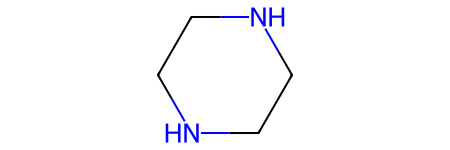

In [8]:
# Compuestos de filtro que contienen un grupo funcional ácido
# substructure = AllChem.MolFromSmiles("C1CCC2=NC3=CC=CC=C3C(=C2C1)N")

substructure = AllChem.MolFromSmiles("C1NCCNC1")#piperazine
# substructure = AllChem.MolFromSmiles("c1cnoc1")
substructure

In [9]:
#Creamos un nuevo dataset donde adicionaremos las moléculas filtradas
dataset_substructure = data[data["Structure"] >= substructure]
dataset_substructure.shape

(305, 1628)

In [10]:
dataset_substructure

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,0.197668,578.805,6.51442,43,11,73.39,6,2,1,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,...,10.752719,80.685788,578.373310,6.498577,8198,73,228.0,271.0,11.194444,9.527778
53,0.130961,649.905,7.88000,47,13,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCCCNc4c5c(...,...,10.877802,99.271617,649.345047,6.907926,11311,80,254.0,304.0,11.395833,10.305556
133,0.178089,607.824,6.70970,44,10,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCNc4c5c(nc6...,...,10.863431,96.099450,607.298097,7.144683,8754,77,242.0,292.0,10.645833,9.555556
157,0.158774,621.851,7.09980,45,11,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCNc4c5c(nc...,...,10.868245,97.157639,621.313747,7.060383,9561,78,246.0,296.0,10.895833,9.805556
160,0.509544,477.741,5.18780,35,10,34.64,5,1,1,CCN(CCCN1CCN(CCNc2c3c(nc4ccccc24)CCCC3)CC1)C1C...,...,10.423739,71.382235,477.383147,5.821746,4662,55,182.0,213.0,8.250000,7.888889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5198,0.734584,375.488,2.30350,27,7,43.86,3,0,0,CC1CCCCN1CCCN1CC(=O)N(CCc2ccc(F)cc2)CC1=O,...,10.030517,61.753334,375.232205,6.583021,2240,39,136.0,155.0,8.638889,6.000000
5206,0.229691,566.834,7.52112,42,12,40.63,5,1,1,Cc1c(OCc2ccccc2)cccc1N1CCN(CCCCCCNc2c3c(nc4c2C...,...,10.626558,79.348689,566.398462,6.156505,8235,67,220.0,258.0,9.722222,9.361111
5213,0.691745,383.448,1.55480,28,8,71.97,5,0,0,COc1ccc(CCN2CC(=O)N(CCc3ccccn3)CC2=O)cc1OC,...,10.085434,62.945006,383.184506,7.229896,2420,42,140.0,161.0,8.888889,6.416667
5223,0.602193,395.528,2.99060,28,6,45.55,6,0,1,Cn1c(=O)sc2cc(C(=O)CCN3CCN(Cc4ccccc4)CC3)ccc21,...,10.174392,77.535704,395.166748,7.455976,2492,42,148.0,173.0,8.000000,6.111111


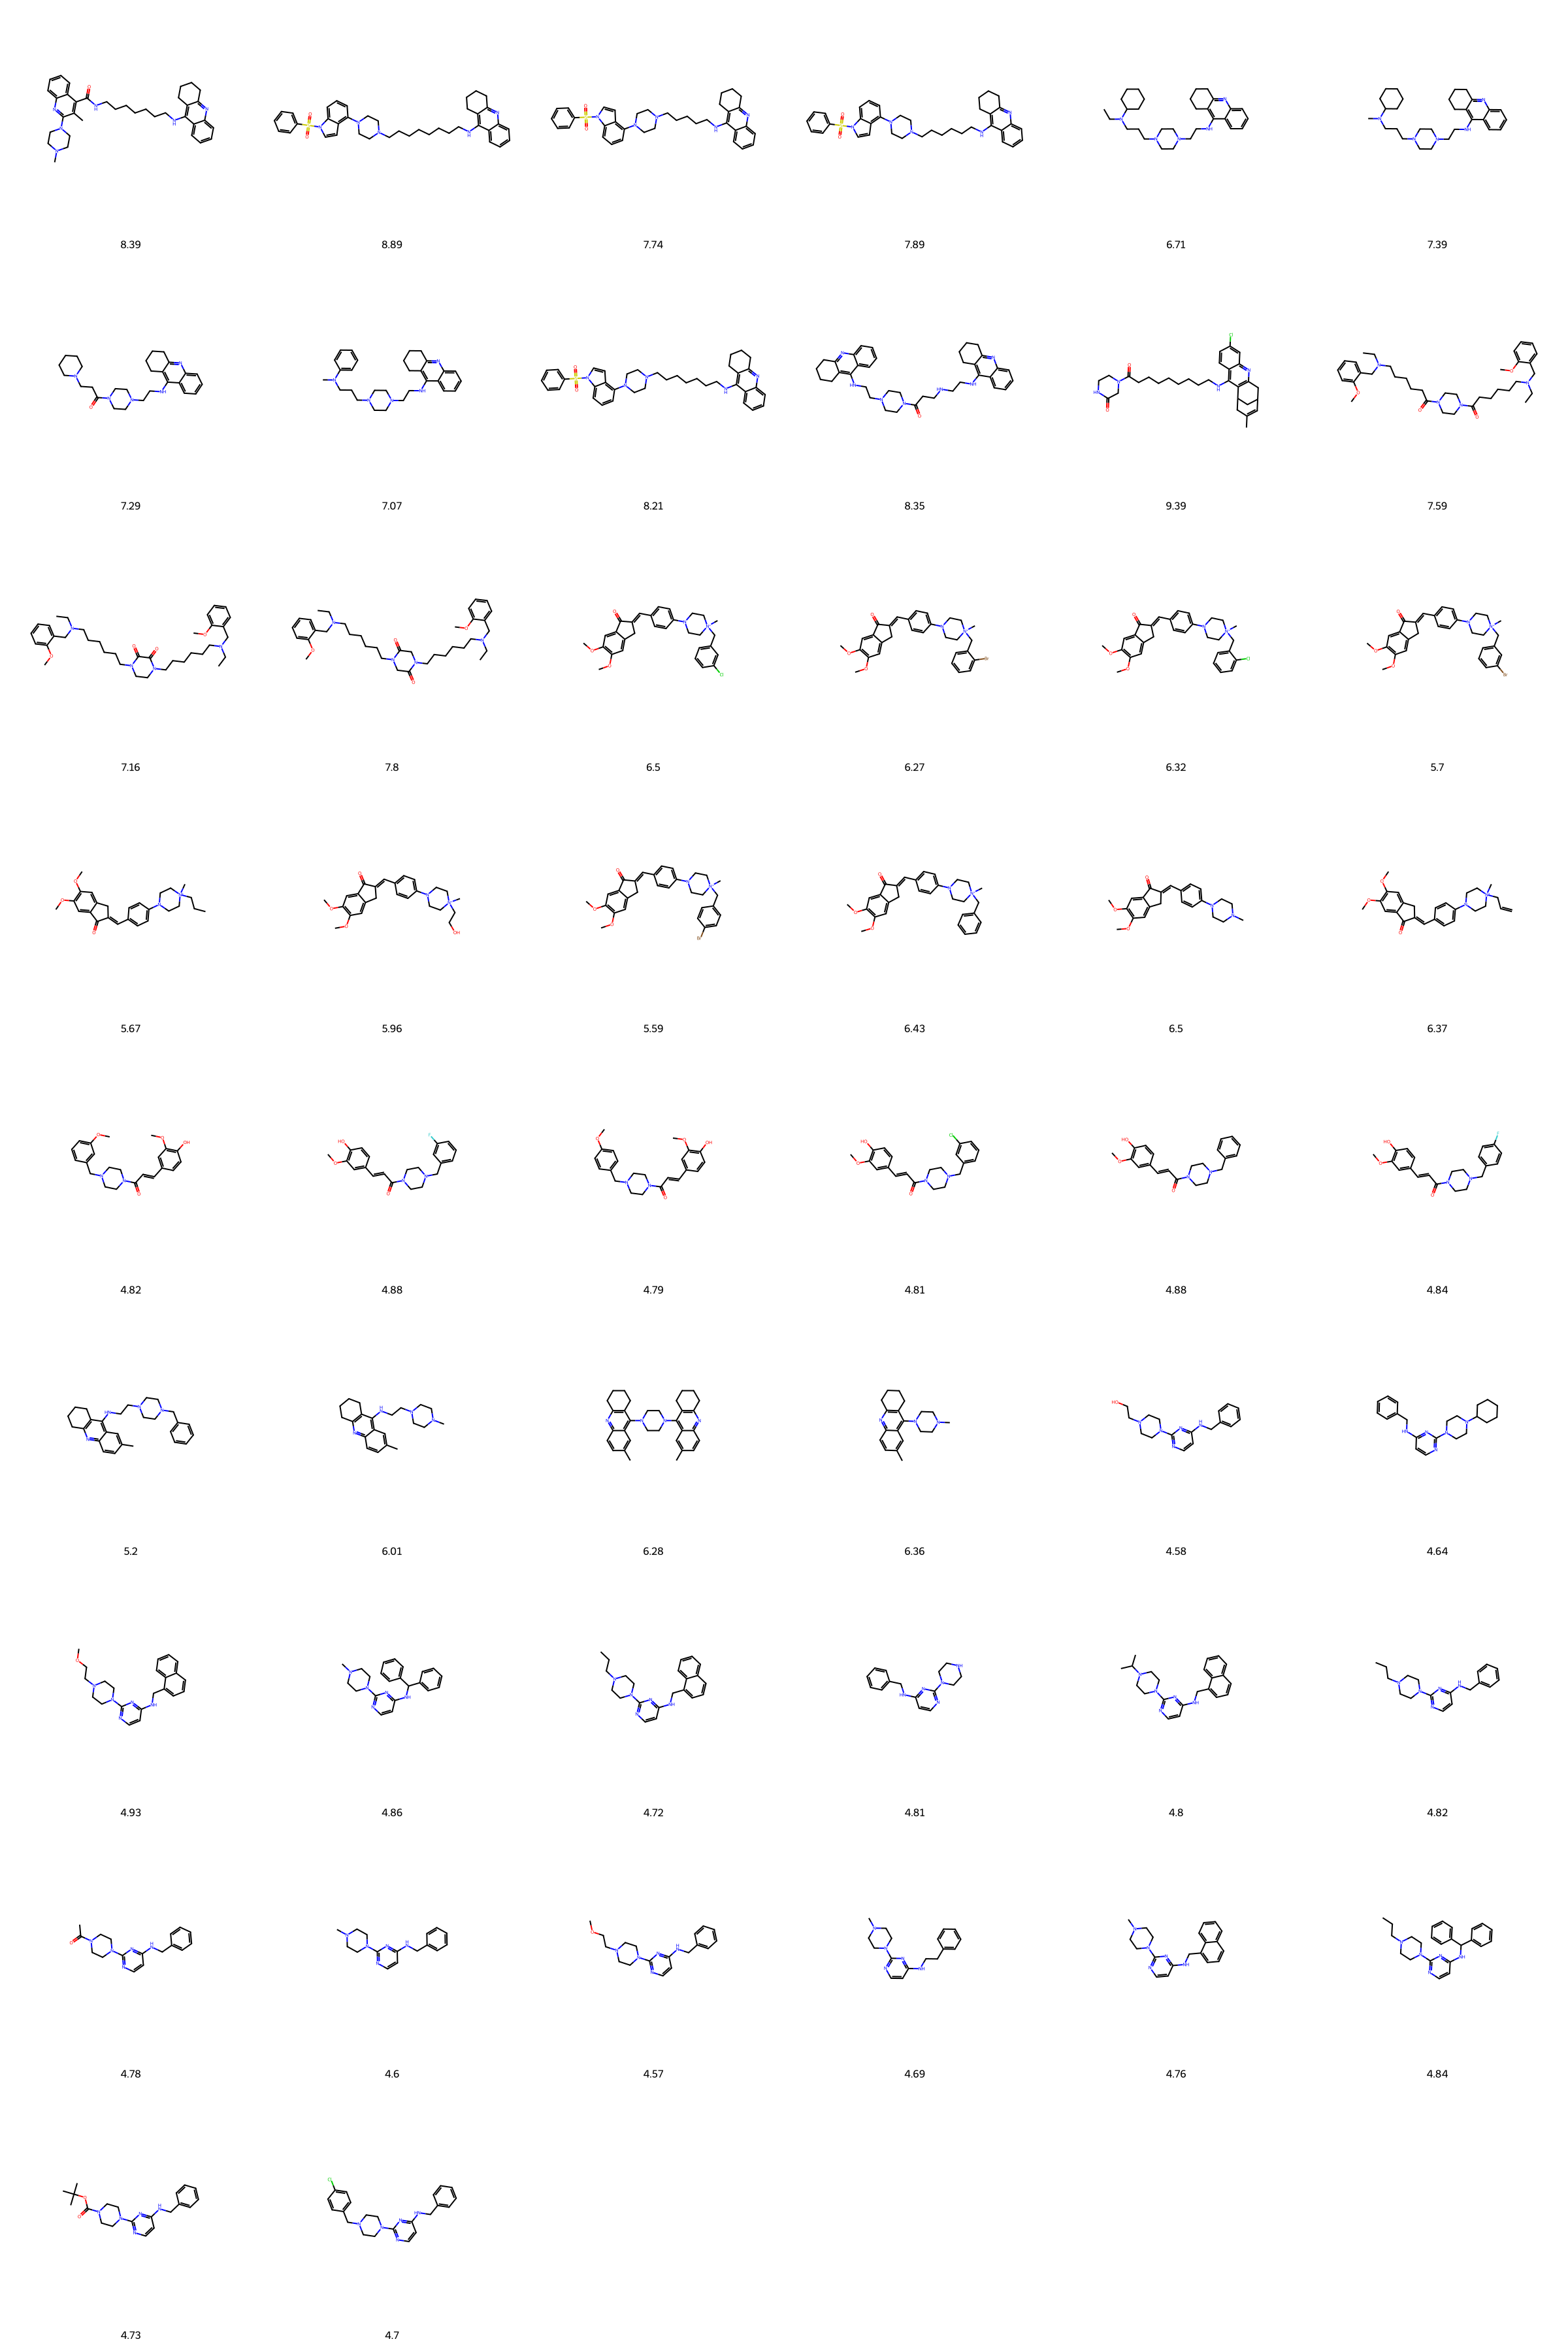

In [11]:
#Visualizamos los elementos filtrados
from rdkit.Chem import Draw
Draw.MolsToGridImage([x for x in dataset_substructure["Structure"]],
                     legends=[str(x) for x in dataset_substructure[ 'pChEMBL Value']],
                     subImgSize=(400,400), molsPerRow=6)

[04:34:03] DEPRECATION WARNING: please use MorganGenerator


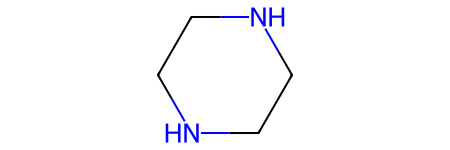

In [12]:
# Encontremos compuestos similares a aspirina
query = AllChem.MolFromSmiles('C1NCCNC1')#'O=C(C)Oc1ccccc1C(=O)O' aspirin
#query = AllChem.MolFromSmiles('SS')#'O=C(C)Oc1ccccc1C(=O)O' aspirin
query_fps = AllChem.GetMorganFingerprintAsBitVect(query, 2, nBits=4096) #C[C@@H](C1=CC2=C(C=C1)C=C(C=C2)OC)C(=O)O'
query

In [13]:
# Calcular las huellas dactilares de todos los compuestos (total 2904)
all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
len(all_Mfpts)

Se truncaron las últimas líneas 5000 del resultado de transmisión.
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use MorganGenerator
[04:34:03] DEPRECATION WARNING: please use Morga

5254

In [14]:
# Calculando el coeficiente de Tanimoto del compuesto de consulta (query) frente a cada uno de los compuestos en el conjunto de datos
# los coloca en la lista
Tanimoto_similarity = [DataStructs.FingerprintSimilarity(query_fps, x, metric=DataStructs.CosineSimilarity) for x in all_Mfpts]

In [15]:
# Coloca los valores del coeficiente de Tanimoto en el dataframe
data["tanimoto_values"] = Tanimoto_similarity

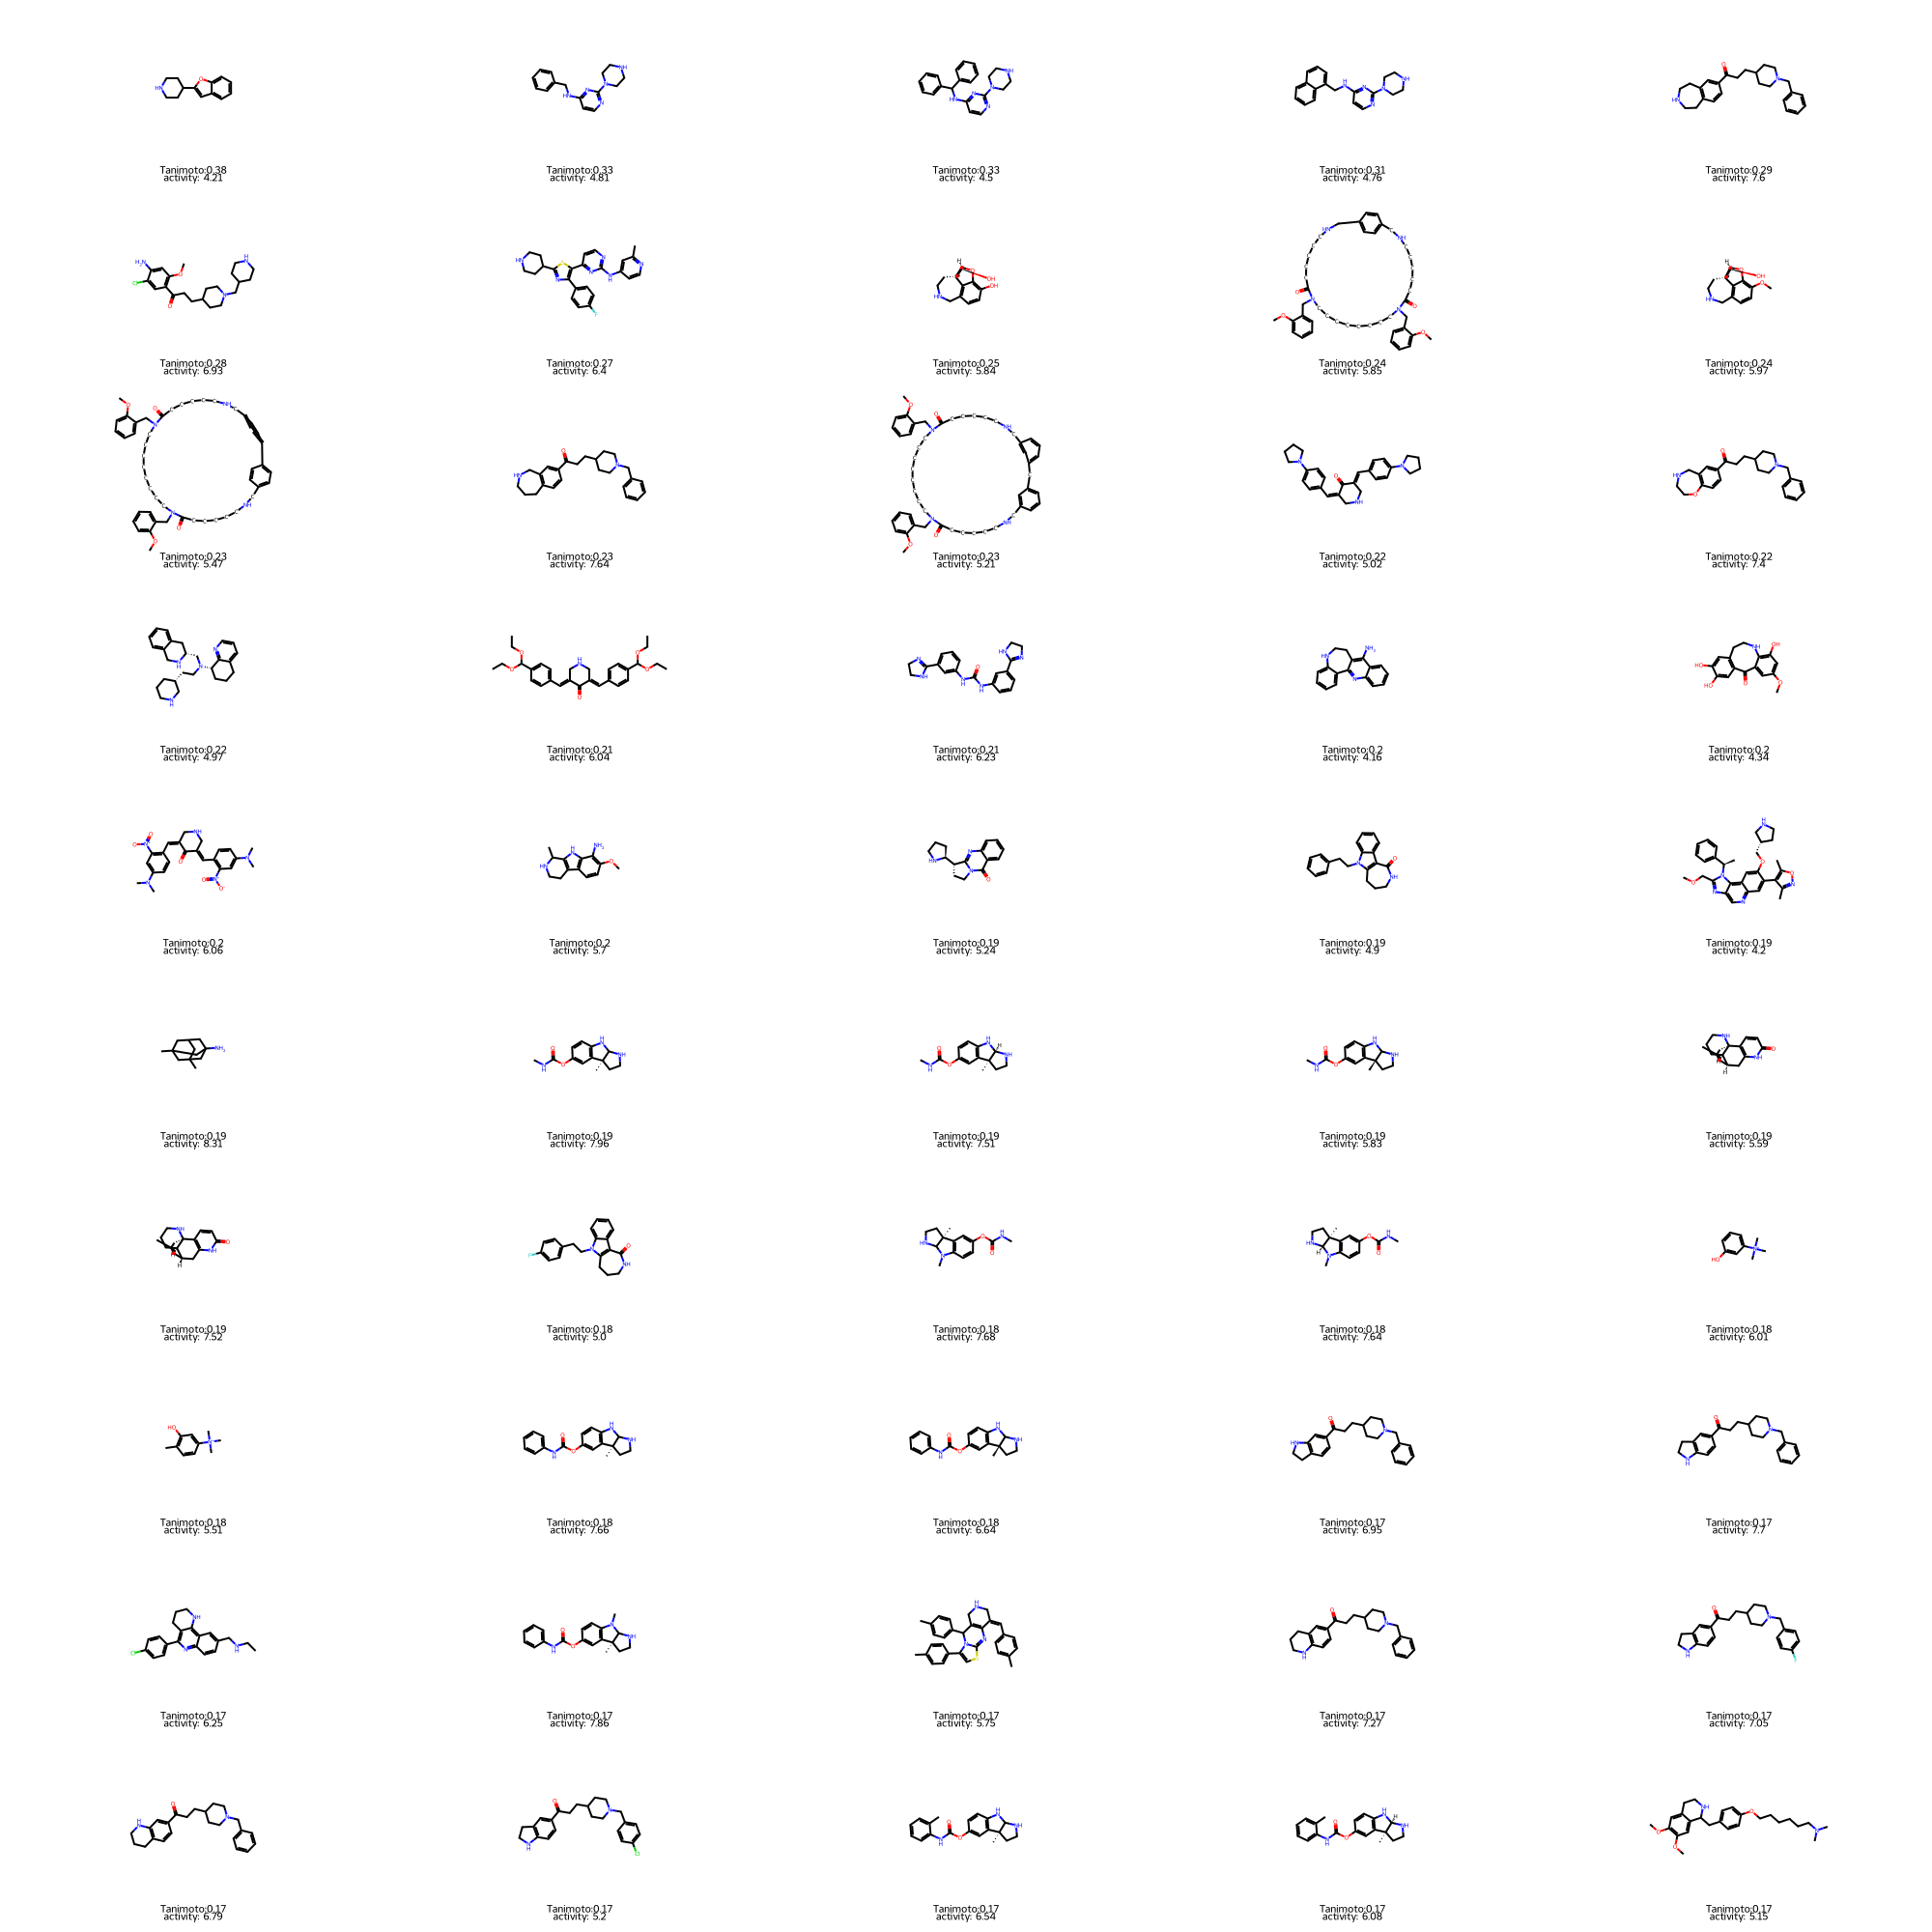

In [16]:
# Ordena los valores del coeficiente de Tanimoto en orden decreciente
dataset_sorted = data.sort_values(['tanimoto_values'],ascending=False)
# Mostrar estructuras y valores de coeficientes de Tanimoto.
Draw.MolsToGridImage([x for x in dataset_sorted["Structure"]],#[:50],
                    # maxMols=100,
                     legends=['Tanimoto:'+str(round(x,2)) + '\n'
                              'activity: '+str(y)
                              for x,y in zip(dataset_sorted.tanimoto_values, dataset_sorted['pChEMBL Value'])],
                     subImgSize=(400,200), molsPerRow=5)

In [17]:
dataset_sorted.shape

(5254, 1629)

In [18]:
# Podemos usar un valor umbral para filtrar compuestos.
s = dataset_sorted[dataset_sorted['tanimoto_values'] >= 0.2]
s.shape

(19, 1629)

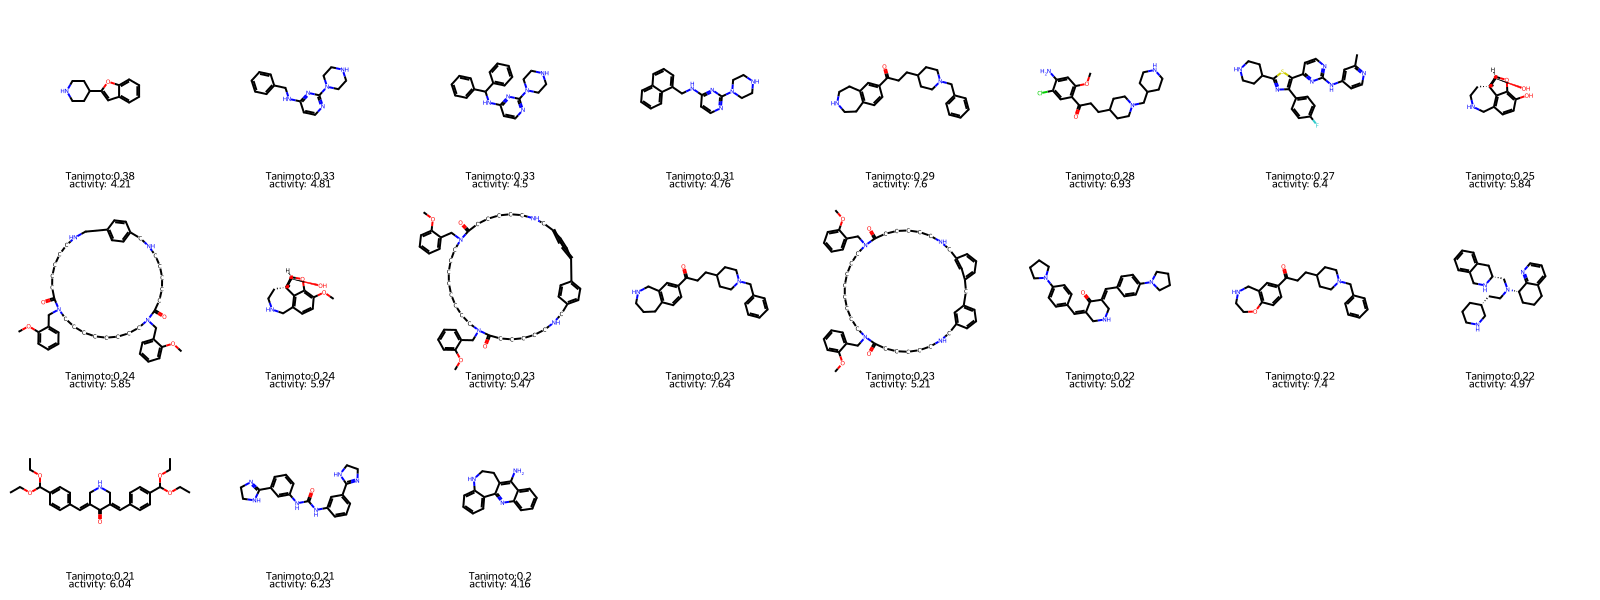

In [19]:
# Mostrar estructuras y valores de coeficientes de Tanimoto.
Draw.MolsToGridImage([x for x in s["Structure"]],#[451:850],
                     maxMols=1000,
                     legends=['Tanimoto:'+str(round(x,2)) + '\n'
                              'activity: '+str(y) for x,y in zip(s.tanimoto_values, s['pChEMBL Value'])], subImgSize=(200,200), molsPerRow=8)

In [20]:
data = s.copy()

In [21]:
data = dataset_substructure.copy()

In [22]:
data = pd.concat([data, dataset_substructure])
data

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,0.197668,578.805,6.51442,43,11,73.39,6,2,1,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,...,10.752719,80.685788,578.373310,6.498577,8198,73,228.0,271.0,11.194444,9.527778
53,0.130961,649.905,7.88000,47,13,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCCCNc4c5c(...,...,10.877802,99.271617,649.345047,6.907926,11311,80,254.0,304.0,11.395833,10.305556
133,0.178089,607.824,6.70970,44,10,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCNc4c5c(nc6...,...,10.863431,96.099450,607.298097,7.144683,8754,77,242.0,292.0,10.645833,9.555556
157,0.158774,621.851,7.09980,45,11,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCNc4c5c(nc...,...,10.868245,97.157639,621.313747,7.060383,9561,78,246.0,296.0,10.895833,9.805556
160,0.509544,477.741,5.18780,35,10,34.64,5,1,1,CCN(CCCN1CCN(CCNc2c3c(nc4ccccc24)CCCC3)CC1)C1C...,...,10.423739,71.382235,477.383147,5.821746,4662,55,182.0,213.0,8.250000,7.888889
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5198,0.734584,375.488,2.30350,27,7,43.86,3,0,0,CC1CCCCN1CCCN1CC(=O)N(CCc2ccc(F)cc2)CC1=O,...,10.030517,61.753334,375.232205,6.583021,2240,39,136.0,155.0,8.638889,6.000000
5206,0.229691,566.834,7.52112,42,12,40.63,5,1,1,Cc1c(OCc2ccccc2)cccc1N1CCN(CCCCCCNc2c3c(nc4c2C...,...,10.626558,79.348689,566.398462,6.156505,8235,67,220.0,258.0,9.722222,9.361111
5213,0.691745,383.448,1.55480,28,8,71.97,5,0,0,COc1ccc(CCN2CC(=O)N(CCc3ccccn3)CC2=O)cc1OC,...,10.085434,62.945006,383.184506,7.229896,2420,42,140.0,161.0,8.888889,6.416667
5223,0.602193,395.528,2.99060,28,6,45.55,6,0,1,Cn1c(=O)sc2cc(C(=O)CCN3CCN(Cc4ccccc4)CC3)ccc21,...,10.174392,77.535704,395.166748,7.455976,2492,42,148.0,173.0,8.000000,6.111111


In [23]:
#función de Culsterificación
def TaylorButina_Cluster(fpts, distThresh = 0.5):
    # generate distance matrix:
    dist_matrix = []
    nfpts = len(fpts)
    for i in tqdm.notebook.tqdm(range(1,nfpts)):

        # generate Tanimoto similary
        Tanimoto_coefficients = DataStructs.BulkTanimotoSimilarity(fpts[i],fpts[:i])
        dist_matrix.extend([1 - j for j in Tanimoto_coefficients])

    # cluster the Tanimoto scores using Butina:
    clusters = Butina.ClusterData(dist_matrix, nfpts, distThresh, isDistData=True)
    cluster_id_list = [0] * nfpts
    for idx,cluster in enumerate(clusters,1):
        for member in cluster:
            cluster_id_list[member] = idx
    return cluster_id_list

In [24]:
from IPython.utils import io
import tqdm.notebook
import os, os.path, sys, random, subprocess
total = 100

In [25]:
with tqdm.notebook.tqdm(total=total) as pbar:
    with io.capture_output() as captured:
      pbar.update(0)
      all_Mfpts = [AllChem.GetMorganFingerprintAsBitVect(mol, 2, nBits=4096) for mol in data.Structure]
      pbar.update(100)


  0%|          | 0/100 [00:00<?, ?it/s]

In [26]:
cluster_id = TaylorButina_Cluster(all_Mfpts, distThresh=0.6)

  0%|          | 0/609 [00:00<?, ?it/s]

In [27]:
# Number of clusters
len(np.unique(cluster_id))

52

In [28]:
#creamos un nuevo dataframe donde agregaremos la información del cluster
#dataset = dataset[['Molecule ChEMBL ID','SMILES','Structure', 'pChEMBL Value']] # Selecciona algunas columnas y agrega una columna de número de cluster
data['Cluster_number'] = cluster_id #Colocamos la identificación del clúster en el dataframe.
data.head() #observar los primeros diez elementos del dataframe

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,Activity,SMILES,...,SRW10,TSRW10,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2
0,0.197668,578.805,6.51442,43,11,73.39,6,2,1,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,...,10.752719,80.685788,578.373310,6.498577,8198,73,228.0,271.0,11.194444,9.527778
53,0.130961,649.905,7.88000,47,13,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCCCNc4c5c(...,...,10.877802,99.271617,649.345047,6.907926,11311,80,254.0,304.0,11.395833,10.305556
133,0.178089,607.824,6.70970,44,10,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCNc4c5c(nc6...,...,10.863431,96.099450,607.298097,7.144683,8754,77,242.0,292.0,10.645833,9.555556
157,0.158774,621.851,7.09980,45,11,70.47,7,1,1,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCNc4c5c(nc...,...,10.868245,97.157639,621.313747,7.060383,9561,78,246.0,296.0,10.895833,9.805556
160,0.509544,477.741,5.18780,35,10,34.64,5,1,1,CCN(CCCN1CCN(CCNc2c3c(nc4ccccc24)CCCC3)CC1)C1C...,...,10.423739,71.382235,477.383147,5.821746,4662,55,182.0,213.0,8.250000,7.888889


#Cluster

In [29]:
import plotly.express as px
import molplotly

In [30]:
# prompt: con fig haz una gráfica de burbuja

fig = px.scatter(data, y='pChEMBL Value', x="Cluster_number", size=round((0.1*data["MolWt"]),2), color="MolWt",color_continuous_scale=px.colors.diverging.Portland,
                 color_continuous_midpoint=560,
                 hover_name="Molecule ChEMBL ID", #log_x=True,
                 size_max=20,
                 title="Gráfica de Burbujas: Actividad vs Peso Molecular coloreado por Cluster",
                 #width=1550,
                # height=900,
                 labels={"pChEMBL Value": "Actividad (pChEMBL Value)", "MolWt": "Peso Molecular (MolWt)", "Cluster_number": "Número de Cluster"})
fig.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')

app = molplotly.add_molecules(
    fig=fig,
    df=data,
    smiles_col="SMILES",
    width=250,
    title_col="Molecule ChEMBL ID",
    caption_cols=['MolWt'],
    #caption_cols=["y_pred", "y_true", "Molecular Weight"],
    #show_coords=False,
    alpha= 0.7,
    mol_alpha= 0.8
)

app.run(port=871, height=750)


<IPython.core.display.Javascript object>

In [31]:
#Asigna un número a cada cluster y cuenta las estructuras en cada uno
#dataset.groupby('Cluster_number')['Structure'].count()

In [32]:
# prompt: haz una grafica de barras de cluste_ number y structure

import plotly.express as px

# Assuming 'dataset' is your DataFrame with 'Cluster_number' and 'Structure' columns
cluster_counts = data.groupby('Cluster_number')['Structure'].count().reset_index()

fig = px.bar(cluster_counts, x='Cluster_number', y='Structure',
             labels={'Cluster_number': 'Cluster Number', 'Structure': 'Number of Structures'},
             title='Number of Structures per Cluster')

fig.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig.show()



In [33]:
# Sort clusters
dataset_sorted = data.sort_values(["Cluster_number"])#.head(150)

# from rdkit.Chem import Draw
im = Draw.MolsToGridImage([x for x in dataset_sorted["Structure"]][:125], maxMols=200,
                     legends=[str(x) for x in dataset_sorted.Cluster_number], subImgSize=(350,350), molsPerRow=3)
im

In [34]:
# prompt: reinicia los indices da dataset:cs_sorted

# Reset index of dataset_sorted
dataset_sorted = dataset_sorted.reset_index(drop=True)

In [35]:
dataset_sorted.to_excel("AZH_QSAR.xlsx")


# Espacio Químico

In [36]:
# prompt: de df filtered quédate con MolWt, LogP, RB,TPSA,HBA,HDB
data_k = data[['MolWt', 'LogP', 'RB', 'TPSA', 'HBA', 'HDB']]
# Normalizar datos
from sklearn.preprocessing import StandardScaler
data_std = StandardScaler().fit_transform(data_k)
# pca.fit
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_results = pca.fit_transform(data_std)
#pca_results
# Seleccionar impormación complementaria
label = data[[ "SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID',        'pChEMBL Value',        'Molecule Name']]
label = label.to_numpy()
# Concatenar arrays de numpy
arr = np.concatenate((label, pca_results), axis = 1)
# Crear un nuevo dataframe
pca_dataset = pd.DataFrame(data=arr, columns = ["SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID',      'pChEMBL Value',        'Molecule Name',
                                                'component1', 'component2', 'component3']) # Removed 'component3'

#pca_dataset.head(2)

In [37]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(pca.n_components):
  loadings.append(pca.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_k.columns)
# Renombramos las columnas
pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)
# @title
from plotly.subplots import make_subplots
import plotly.graph_objects as go
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC para el Espacio Químico",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
#figx.show()# Muestra la figura

if figx is not None:
  print("Gráfica de barras creada correctamente.")
else:
  print("No se pudo crear la gráfica de barras.")

PC1 = 0.5444*MolWt + 0.3266*LogP + 0.4641*RB + 0.3990*TPSA + 0.4608*HBA + 0.1002*HDB
PC2 = 0.2018*MolWt + 0.5340*LogP + 0.2678*RB + -0.5067*TPSA + -0.3441*HBA + -0.4767*HDB
PC3 = 0.0602*MolWt + 0.2297*LogP + 0.1412*RB + -0.2006*TPSA + -0.3885*HBA + 0.8559*HDB
Gráfica de barras creada correctamente.


#2D

In [38]:
import plotly.express as px
import molplotly

In [39]:
# prompt: repite la ultima gráfica con plotly
dato1='component1'
#dato2='Activity'
dato2='pChEMBL Value'
dato3='component2'
#_________
dato4='pChEMBL Value'
# Convert 'pChEMBL Value' to numeric, coercing errors to NaN
pca_dataset['pChEMBL Value'] = pd.to_numeric(pca_dataset['pChEMBL Value'], errors='coerce')
# Drop rows with NaN values in 'pChEMBL Value' that resulted from coercion
pca_dataset.dropna(subset=['pChEMBL Value'], inplace=True)

# Create a bubble chart using Plotly
fig_bubble = px.scatter(pca_dataset,
                        x='component1',
                        y='component2',
                        size=60*3**(0.8*pca_dataset['pChEMBL Value']),  # Use 'pChEMBL Value' for bubble size
                        color='pChEMBL Value', # Use 'pChEMBL Value' for color mapping
                        title='Gráfico de Burbujas: PC1 vs PC2 (Tamaño y Color por pChEMBL Value)',
                        labels={'component1': 'Componente Principal 1 (PC1)',
                                'component2': 'Componente Principal 2 (PC2)',
                                'pChEMBL Value': 'pChEMBL Value'},
                        color_continuous_scale='viridis',
                        height=600)

# Update layout for better appearance
fig_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_bubble.update_xaxes(showgrid=True, gridcolor='lightgrey')
fig_bubble.update_yaxes(showgrid=True, gridcolor='lightgrey')


# Set background color to white
fig_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
#figa.update_layout(legend=dict(font=dict(size=10)))  # Increase legend font size
#fig.update_layout(font=dict(size=8)) # Increase font size for all text elements
fig_bubble.update_layout(hoverlabel_font_size=20)
#figa.update_layout(showlegend=False) # This line removes the legend
#figa.update_layout(legend=dict(orientation="h", yanchor="bottom", y=-20.0, xanchor="right", x=0))
fig_bubble.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
#fig_bubble.update_traces(marker=dict(size=12)) # Increase marker size
# Remove grid lines
fig_bubble.update_xaxes(showgrid=False)
fig_bubble.update_yaxes(showgrid=False)
# Show the Plotly figure
#fig_bubble.show()

app_marker = molplotly.add_molecules(fig=fig_bubble,
                                     #_____________dataframe___________________
                                     df=pca_dataset,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________
                                     #color_col='G',
                                     #color_col=dato2,
                                     #_________________________________________
                                    fontsize=20, width=350,
                                     caption_cols=[dato2],
                                     show_coords=False)
app_marker.run(port=8060)
#fig_pca.show()
figx.update_layout(width=800, height=250)
figx.show()

<IPython.core.display.Javascript object>

# Representación del Espacio Químico por T-SNE

In [40]:
data_std_ =  pd.DataFrame(data_std, columns=data_k.columns)
data_std_

,MolWt,LogP,RB,TPSA,HBA,HDB
0,1.347412,2.139129,1.436529,0.355004,0.209934,1.914434
1,2.081410,3.137755,2.115818,0.247906,0.786779,0.361502
2,1.646988,2.281934,1.096885,0.247906,0.786779,0.361502
3,1.791796,2.567208,1.436529,0.247906,0.786779,0.361502
4,0.304080,1.168994,1.096885,-1.066236,-0.366911,0.361502
...,...,...,...,...,...,...
605,-0.751526,-0.940247,0.077951,-0.728073,-1.520602,-1.191430
606,1.223829,2.875312,1.776174,-0.846540,-0.366911,0.361502
607,-0.669351,-1.487758,0.417596,0.302922,-0.366911,-1.191430
608,-0.544643,-0.437782,-0.261693,-0.666089,0.209934,-1.191430


In [41]:
dataset = data.copy()

In [42]:
# @title
## Entrenar modelo t-SNE
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import plotly.express as px
import molplotly

# Select relevant columns from the entire dataset
data_tsne = dataset[['MolWt', 'LogP', 'RB', 'TPSA', 'HBA', 'HDB']].copy()

# Scale the data
data_tsne = StandardScaler().fit_transform(data_tsne)

# Perform t-SNE
# Reduce perplexity to a value less than the number of samples if necessary
tsne = TSNE(n_components=3, verbose=1, perplexity=10, max_iter=10000, early_exaggeration=1, random_state=RANDOM_STATE) # Increased perplexity to a reasonable value for the full dataset
tsne_results = tsne.fit_transform(data_tsne)

# Prepare supplementary information from the entire dataset
label_cols = ["SMILES", "Structure", 'Activity', 'Cluster_number', 'Molecule ChEMBL ID', 'pChEMBL Value', 'Molecule Name']
label = dataset[label_cols].copy()
label = label.to_numpy()

# Concatenate arrays of numpy
arr = np.concatenate((label, tsne_results), axis=1)

# Create a new dataframe
tsne_dataset = pd.DataFrame(data=arr,
                            columns=label_cols + ['axis1', 'axis2', 'axis3'])

# Convert relevant columns to appropriate types (they are objects after concatenation)
tsne_dataset['Activity'] = pd.to_numeric(tsne_dataset['Activity'], errors='coerce')
tsne_dataset['Cluster_number'] = pd.to_numeric(tsne_dataset['Cluster_number'], errors='coerce')
tsne_dataset['pChEMBL Value'] = pd.to_numeric(tsne_dataset['pChEMBL Value'], errors='coerce')
tsne_dataset['axis1'] = pd.to_numeric(tsne_dataset['axis1'], errors='coerce')
tsne_dataset['axis2'] = pd.to_numeric(tsne_dataset['axis2'], errors='coerce')
tsne_dataset['axis3'] = pd.to_numeric(tsne_dataset['axis3'], errors='coerce')


# You can uncomment and adapt these lines if you have 'cn_s' and 'cn' columns in your original dataset
# tsne_dataset = tsne_dataset.sort_values(by=['cn_s'])
# tsne_dataset = tsne_dataset.drop_duplicates(subset='SMILES')




[t-SNE] Computing 31 nearest neighbors...
[t-SNE] Indexed 610 samples in 0.013s...
[t-SNE] Computed neighbors for 610 samples in 0.015s...
[t-SNE] Computed conditional probabilities for sample 610 / 610
[t-SNE] Mean sigma: 0.398560
[t-SNE] KL divergence after 250 iterations with early exaggeration: -0.681573
[t-SNE] KL divergence after 10000 iterations: -3.378427


In [43]:
# Graficar

#_______________________________________________________________________________________________________


fig_tsne2d = px.scatter(tsne_dataset,
                      x='axis1', y='axis2',
                      color='Cluster_number', # Using Cluster_number for color
                      title='t-SNE (2D) colored by Cluster Number',
                      size=60*3**(0.8*pca_dataset['pChEMBL Value']),  # Use 'pChEMBL Value' for bubble size
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d.update_traces(marker=dict(size=8)) # Adjusted marker size for larger dataset
fig_tsne2d.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size


app_marker2d = molplotly.add_molecules(fig=fig_tsne2d,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                      #  title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       width=350, fontsize= 15,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       show_coords=False
                                       )
#_________________________________________________________________________________________________________


fig_tsne3d = px.scatter_3d(tsne_dataset,
                      x='axis1', y='axis3', z='axis2',
                      color='Cluster_number', # Using Cluster_number for color
                      title='t-SNE (3D) colored by Cluster Number',
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d.update_traces(marker=dict(size=8)) # Adjusted marker size for larger dataset
fig_tsne3d.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size


app_marker3d = molplotly.add_molecules(fig=fig_tsne3d,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                      #  title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       svg_size=200,
                                       show_coords=False,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       fontsize=15, width=210)

#_____________________________________________________________________________________________________
app_marker2d.run(port=8060)
app_marker3d.run(port=8061) # Use a different port for the second app
#fig_tsne2d.show()
#fig_tsne3d.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
# prompt: del gráfico anterior hazlos gráficos de burbujas con ac

# Update the existing 2D t-SNE scatter plot to a bubble chart
fig_tsne2d_bubble = px.scatter(tsne_dataset,
                      x='axis1', y='axis2',
                      color='pChEMBL Value', # Using Cluster_number for color
                      title='t-SNE (2D) Gráfico de Burbujas: Tamaño y Color por pChEMBL Value',
                      size=60*3**(0.8*tsne_dataset['pChEMBL Value']),  # Use 'pChEMBL Value' for bubble size
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne2d_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne2d_bubble.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne2d_bubble.update_traces(marker=dict(sizemin=5)) # Adjust minimum marker size
fig_tsne2d_bubble.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size
fig_tsne2d_bubble.update_xaxes(showgrid=False)
fig_tsne2d_bubble.update_yaxes(showgrid=False)


app_marker2d_bubble = molplotly.add_molecules(fig=fig_tsne2d_bubble,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                      #  title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       width=350, fontsize= 15,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       show_coords=False
                                       )

# Update the existing 3D t-SNE scatter plot to a bubble chart
fig_tsne3d_bubble = px.scatter_3d(tsne_dataset,
                      x='axis1', y='axis3', z='axis2',
                      color='pChEMBL Value', # Using Cluster_number for color
                      title='t-SNE (3D) Gráfico de Burbujas: Tamaño y Color por pChEMBL Value',
                      size=60*3**(0.8*tsne_dataset['pChEMBL Value']), # Use 'pChEMBL Value' for bubble size
                      hover_data={'Cluster_number':True, 'Activity':True, 'pChEMBL Value':True, 'axis1': False, 'axis2': False, 'axis3':False},
                      hover_name='Molecule ChEMBL ID',
                      width=900,height=700)

# Set background color to white
fig_tsne3d_bubble.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_tsne3d_bubble.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_tsne3d_bubble.update_traces(marker=dict(sizemin=5)) # Adjust minimum marker size
fig_tsne3d_bubble.update_layout(hoverlabel_font_size=15) # Adjusted hover label font size


app_marker3d_bubble = molplotly.add_molecules(fig=fig_tsne3d_bubble,
                                       df=tsne_dataset,
                                       smiles_col='SMILES',
                                      #  title_col='Molecule ChEMBL ID',
                                       color_col='Cluster_number',
                                       svg_size=200,
                                       show_coords=False,
                                       caption_cols=['Cluster_number','pChEMBL Value'],
                                       fontsize=15, width=210)

# Run the updated apps on new ports to avoid conflicts
app_marker2d_bubble.run(port=8062)
app_marker3d_bubble.run(port=8063)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# QSAR

In [45]:
#Guardamos la data como una nueva variable

#df_y = pd.read_excel("Actividad.xlsx") #Esta es opcional opción 1
df_y_ = data["pChEMBL Value"] #Esta es opcional opción 2

In [46]:
# Importamos datos
#_____________________________________________
df_x_ = data.copy()
df_x_ = df_x_.drop('Activity', axis=1) # Este renglón puede ser útil #Opción 2
df_x_ = df_x_.drop('pChEMBL Value', axis=1)
df_x_ = df_x_.drop('Cluster_number', axis=1)
df_x_ = df_x_.select_dtypes("number")  # quitar non_numeric
#_____________________________________________
df_data = df_x_.assign(Activity=df_y_)
#df_data

## Load data

In [47]:
# cargamos data
#df_x = pd.read_csv("nlz_data.csv")
#df_x = df_x.iloc[:, 1:]  # quitar "No."
df_x_ = df_x_.select_dtypes("number")  # quitar non_numeric
#df_y = pd.read_csv("nlz_activity.csv")

df_data = df_x_.assign(Activity=df_y_)
#df_data

In [48]:
print(list(df_data.columns))

['QED', 'MolWt', 'LogP', 'HAC', 'RB', 'TPSA', 'HBA', 'HDB', 'nAcid', 'nBase', 'SpAbs_A', 'SpMax_A', 'SpDiam_A', 'SpAD_A', 'SpMAD_A', 'LogEE_A', 'VE1_A', 'VE2_A', 'VE3_A', 'VR1_A', 'VR2_A', 'VR3_A', 'nAromAtom', 'nAromBond', 'nAtom', 'nHeavyAtom', 'nSpiro', 'nBridgehead', 'nHetero', 'nH', 'nB', 'nC', 'nN', 'nO', 'nS', 'nP', 'nF', 'nCl', 'nBr', 'nI', 'nX', 'ATS0dv', 'ATS1dv', 'ATS2dv', 'ATS3dv', 'ATS4dv', 'ATS5dv', 'ATS6dv', 'ATS7dv', 'ATS8dv', 'ATS0d', 'ATS1d', 'ATS2d', 'ATS3d', 'ATS4d', 'ATS5d', 'ATS6d', 'ATS7d', 'ATS8d', 'ATS0s', 'ATS1s', 'ATS2s', 'ATS3s', 'ATS4s', 'ATS5s', 'ATS6s', 'ATS7s', 'ATS8s', 'ATS0Z', 'ATS1Z', 'ATS2Z', 'ATS3Z', 'ATS4Z', 'ATS5Z', 'ATS6Z', 'ATS7Z', 'ATS8Z', 'ATS0m', 'ATS1m', 'ATS2m', 'ATS3m', 'ATS4m', 'ATS5m', 'ATS6m', 'ATS7m', 'ATS8m', 'ATS0v', 'ATS1v', 'ATS2v', 'ATS3v', 'ATS4v', 'ATS5v', 'ATS6v', 'ATS7v', 'ATS8v', 'ATS0se', 'ATS1se', 'ATS2se', 'ATS3se', 'ATS4se', 'ATS5se', 'ATS6se', 'ATS7se', 'ATS8se', 'ATS0pe', 'ATS1pe', 'ATS2pe', 'ATS3pe', 'ATS4pe', 'ATS5pe'

In [49]:
# dividimos train test con stratified
discretizer = sklearn.preprocessing.KBinsDiscretizer(n_bins=12, encode="ordinal", strategy="uniform")
splitter = StratifiedShuffleSplit(n_splits=N_SPLITS, test_size=0.30, random_state=RANDOM_STATE)
# Reshape y_discrete to be a 2D array (n_samples, 1)
y_discrete = discretizer.fit_transform(df_y_.values.reshape(-1, 1))
split, split_test = next(splitter.split(df_x_.values, y_discrete))
fractions = ["train" if i in split else "test" for i in range(df_data.shape[0])]
df_data = df_data.assign(fraction=fractions)
#df_data

In [50]:
df_data.reset_index(drop=True, inplace=True)
#df_data_

In [51]:
# prompt: cuantos train hay cuantos test hay en data[fraction]

df_data['fraction'].value_counts()

,count
fraction,
train,427
test,183


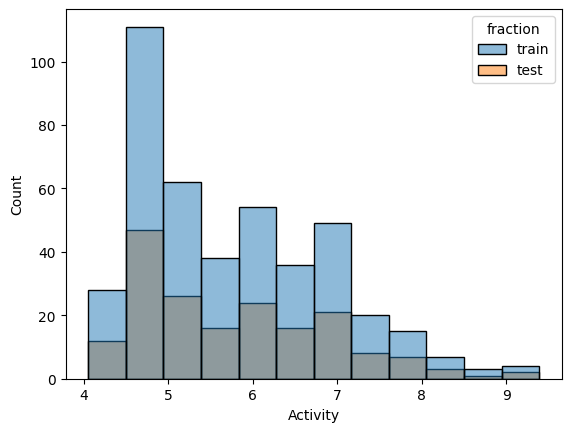

In [52]:
# prompt: con seaborn has un histograma de activity donde se muestre el test y train de fraction

import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(data=df_data, x="Activity", hue="fraction", bins=12)
plt.show()


In [53]:
#df_data = df_data.copy()
#df_data = df_data.drop('Activity', axis=1)

#df_data_s_ = df_data_s_.drop('fraction', axis=1)
df_data

,QED,MolWt,LogP,HAC,RB,TPSA,HBA,HDB,nAcid,nBase,...,MW,AMW,WPath,WPol,Zagreb1,Zagreb2,mZagreb1,mZagreb2,Activity,fraction
0,0.197668,578.805,6.51442,43,11,73.39,6,2,0,1,...,578.373310,6.498577,8198,73,228.0,271.0,11.194444,9.527778,8.39,train
1,0.130961,649.905,7.88000,47,13,70.47,7,1,0,1,...,649.345047,6.907926,11311,80,254.0,304.0,11.395833,10.305556,8.89,train
2,0.178089,607.824,6.70970,44,10,70.47,7,1,0,1,...,607.298097,7.144683,8754,77,242.0,292.0,10.645833,9.555556,7.74,train
3,0.158774,621.851,7.09980,45,11,70.47,7,1,0,1,...,621.313747,7.060383,9561,78,246.0,296.0,10.895833,9.805556,7.89,train
4,0.509544,477.741,5.18780,35,10,34.64,5,1,0,3,...,477.383147,5.821746,4662,55,182.0,213.0,8.250000,7.888889,6.71,train
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
605,0.734584,375.488,2.30350,27,7,43.86,3,0,0,1,...,375.232205,6.583021,2240,39,136.0,155.0,8.638889,6.000000,4.70,test
606,0.229691,566.834,7.52112,42,12,40.63,5,1,0,1,...,566.398462,6.156505,8235,67,220.0,258.0,9.722222,9.361111,7.85,test
607,0.691745,383.448,1.55480,28,8,71.97,5,0,0,0,...,383.184506,7.229896,2420,42,140.0,161.0,8.888889,6.416667,4.70,test
608,0.602193,395.528,2.99060,28,6,45.55,6,0,0,2,...,395.166748,7.455976,2492,42,148.0,173.0,8.000000,6.111111,6.34,test


In [54]:
# sacamos los vectores (x, y) de interés
x_train = df_data[df_data["fraction"] == "train"]
x_train.drop('fraction', axis=1, inplace=True)
x_train.drop('Activity', axis=1, inplace=True)
x_train = x_train.values
#________________________________________
y_train = df_data[df_data["fraction"] == "train"]
y_train = y_train['Activity']
y_train = y_train.values

#_________________________________
#_________________________________
x_test = df_data[df_data["fraction"] == "test"]
x_test.drop('fraction', axis=1, inplace=True)
x_test.drop('Activity', axis=1, inplace=True)
x_test = x_test.values
#________________________________________
y_test = df_data[df_data["fraction"] == "test"]
y_test = y_test['Activity']
#y_test = y_test
y_test = y_test.values


y_train = np.reshape(y_train, -1)
y_test = np.reshape(y_test, -1)

In [55]:
x_train = x_train.astype(float)
y_train = y_train.astype(float)
x_test = x_test.astype(float)
y_test = y_test.astype(float)

x_train

array([[1.97667671e-01, 5.78805000e+02, 6.51442000e+00, ...,
        2.71000000e+02, 1.11944444e+01, 9.52777778e+00],
       [1.30960701e-01, 6.49905000e+02, 7.88000000e+00, ...,
        3.04000000e+02, 1.13958333e+01, 1.03055556e+01],
       [1.78088703e-01, 6.07824000e+02, 6.70970000e+00, ...,
        2.92000000e+02, 1.06458333e+01, 9.55555556e+00],
       ...,
       [5.54999526e-01, 4.77599000e+02, 4.79002000e+00, ...,
        2.23000000e+02, 1.00833333e+01, 7.61111111e+00],
       [6.55692306e-01, 4.14377000e+02, 3.32550000e+00, ...,
        1.53000000e+02, 1.13611111e+01, 5.97222222e+00],
       [3.20116861e-01, 4.79574000e+02, 6.41068000e+00, ...,
        2.23000000e+02, 9.72222222e+00, 7.97222222e+00]])





# Train & Evaluate

In [56]:
# creamos pipeline: el modelo final final
steps = [
    ("var0", VarianceThreshold(MIN_VARIANCE)),
    ("scaling", SCALER),
    ("feat_selector1", FEAT_SELECTOR1),
    ("feat_selector2", FEAT_SELECTOR2),
    ("regressor", REGRESSOR)
]
pipeline = Pipeline(steps, verbose=True)
pipeline = pipeline.fit(x_train, y_train)
pipeline.set_params(verbose=False)
pipeline

[Pipeline] .............. (step 1 of 5) Processing var0, total=   0.0s
[Pipeline] ........... (step 2 of 5) Processing scaling, total=   0.0s
[Pipeline] .... (step 3 of 5) Processing feat_selector1, total=  38.9s
[Pipeline] .... (step 4 of 5) Processing feat_selector2, total=   0.2s
[Pipeline] ......... (step 5 of 5) Processing regressor, total=   0.1s


Pipeline(steps=[('var0', VarianceThreshold(threshold=0)),
                ('scaling', StandardScaler()),
                ('feat_selector1',
                 SelectFromModel(estimator=RandomForestRegressor())),
                ('feat_selector2', PCA(n_components=7, random_state=5712492)),
                ('regressor', SVR())])

In [57]:
# analizamos paso a paso las transformaciones
z = x_train
for (i, step) in enumerate(pipeline[:-1]):
    print(f"Step {pipeline.steps[i][0]} ({i}): {step.__class__.__name__}")
    print(f"  Input: {z.shape}. Output: {step.transform(z).shape}")
    z = step.transform(z)

Step var0 (0): VarianceThreshold
  Input: (427, 1197). Output: (427, 1010)
Step scaling (1): StandardScaler
  Input: (427, 1010). Output: (427, 1010)
Step feat_selector1 (2): SelectFromModel
  Input: (427, 1010). Output: (427, 197)
Step feat_selector2 (3): PCA
  Input: (427, 197). Output: (427, 7)


# resultados


In [58]:
val=True
if val==True:
  # validar accuracy
  metric = "r2"
  # cv = sklearn.model_selection.LeaveOneOut()
  cv = sklearn.model_selection.KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
  cv_scores = sklearn.model_selection.cross_val_score(pipeline, x_train, y_train, cv=cv, verbose=2, scoring=metric)
  scorer = sklearn.metrics.get_scorer(metric)
  pd.DataFrame([{"train": scorer(pipeline, x_train, y_train),
               "cv": np.mean(cv_scores),
               "test": scorer(pipeline, x_test, y_test),
               "metric": metric}])

[CV] END .................................................... total time=  27.6s
[CV] END .................................................... total time=  28.6s
[CV] END .................................................... total time=  27.2s
[CV] END .................................................... total time=  26.8s
[CV] END .................................................... total time=  28.1s
[CV] END .................................................... total time=  28.4s
[CV] END .................................................... total time=  28.8s
[CV] END .................................................... total time=  29.9s
[CV] END .................................................... total time=  32.6s
[CV] END .................................................... total time=  30.9s


[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:  4.8min finished


In [59]:
pd.DataFrame([{"train": scorer(pipeline, x_train, y_train),
               "cv": np.mean(cv_scores),
               "test": scorer(pipeline, x_test, y_test),
               "metric": metric}])

,train,cv,test,metric
0,0.701166,0.588622,0.68645,r2


In [60]:
grid = False
if grid == True:
    # Crear el objeto GridSearchCV
    grid_search = GridSearchCV(pipeline,param_grid,cv=KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE), # o el CV_SPLITTER que definas
                               scoring='r2', # Cambia a 'r2' si es necesario
                               n_jobs=-1, # Usa todos los núcleos disponibles
                               verbose=2 # Imprime progreso
                               )
    # Para ejecutar la búsqueda
    grid_search.fit(x_train, y_train)
    # Para ver los mejores parámetros encontrados
    print("Best parameters:", grid_search.best_params_)
    # Para ver el mejor score obtenido
    print("Best cross-validation score:", grid_search.best_score_)
    # Para obtener el mejor modelo
    best_model = grid_search.best_estimator_

# Grupo de exploración

In [61]:
excel_flag = True
SMILES_LIST = True
comercial = False

In [62]:
smiles_dict = {'Manu021':'CN1C[C@H]2N(CC(C3=CC=C(OC)C=C3)=O)C[C@@H]1C2',
               'Manu022':'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               'Manu023' :'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@H]4CN(C5N(C6=NC(C=CC(Br)=C7)=C7S6)C(CS5)=O)[C@H](C4)C3)C=C21)=O',
               'Manu024': 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu024': 'O=C(C1=CC(F)=C(N2[C@H]3CN(C4N(C5=NC(C=CC(Br)=C6)=C6S5)C(CS4)=O)[C@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu025' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OCC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'Manu026' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(F)C=CC=C6)=N3',
               'Manu027' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=CC=C(F)C=C6)=N3',
               'Manu028' : 'O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5CN4C6=C(C(F)(F)F)C=CC=C6)=N3',
               'Manu029' : 'CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6=NC(C=CC(NC(C)=O)=C7)=C7S6)C(CS5)=O)[C@@H](C4)C3)C=C21)=O',
               'Manu030' : 'O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OC)=C6)=C6S5)C(CS4)=O)[C@@H](C3)C2)C=C17)C(C(O)=O)=CN7C8CC8',
               'ecp_01':'O=C1C2=C(C=C(F)C(N3CCN(C)CC3)=C2)C=NO1'}
comercial_drugs = {#______penicilinas________________________
               'penicilna G' : 'CC1([C@@H](N2[C@H](S1)[C@@H](C2=O)NC(=O)CC3=CC=CC=C3)C(=O)O)C',
               'oxaciline': 'CC1=C(C(=NO1)C2=CC=CC=C2)C(=O)N[C@H]3[C@@H]4N(C3=O)[C@H](C(S4)(C)C)C(=O)O',
               }


In [63]:
xplor = pd.DataFrame()
if excel_flag is True:
  #convierte smiles_dict en un dataframe
  #____DEBES DEFINIR OD Y NOMBRE DEL ARCHIVO
  !gdown --id 1X_-Wkub7b-89rrJ8nN2FxH1f9joorr_d #IMPORTANTE
  excel = pd.read_excel("NAPRONA_CURATED.xlsx") #IMPORTANTE
  # El archivo EXCEL SOLO DEBE TENER DOS columnas: 'SMILES' y 'Cmpd'
  #______________________________________________
  # ! gdown --id 1IGs5emsGuqycnLA47j7YgwWbyb6SWnSL
  # excel = pd.read_excel("kurt_xplor1_.xlsx")
  #_______________________________________________
# }  ! gdown --id 1Z5k3LY4lD8urfTUmGIl3HeEwX6hQaM6l
#   excel = pd.read_excel("valid_smiles3.xlsx")
  #________________________________________________
  # ! gdown --id 1_vE6EPXJYAiPR1g6kBl2uE5u_-aJ1oft
  # excel = pd.read_excel("drugs.xlsx")
  #______________________________________

  # ! gdown --id 1xJlMEy_h5xkBKeVmC9lWuYrEPJx_hFxx
  # excel = pd.read_excel("L9_SMILES.xlsx")
  #______________________________________________

  excel['G'] = 'xplor'
  # excel['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, excel], ignore_index=True)
  print('Un archivo excel se adicionó a xplor')
else:
    print('NO se proceso EXCEL para adicionar a xplor')


if SMILES_LIST is True:
  #convierte smiles_dict en un dataframe
  sl = pd.DataFrame(list(smiles_dict.items()), columns=['Cmpd', 'SMILES'])
  sl['G'] = 'xplor'
  # sl['Cluster_number'] = len(set(cluster_id))+1
  xplor = pd.concat([xplor, sl], ignore_index=True)
  print('Un diccionario con SMILES se adicionó a xplor')
else:
  print('NO se proceso el DICCIONARIO para adicionar a xplor')

if comercial is True:
  #convierte comercial_drugs en un dataframe
  com_drugs = pd.DataFrame(list(comercial_drugs.items()), columns=['Cmpd', 'SMILES'])
  com_drugs['G'] = 'comercial'
  # com_drugs['Cluster_number'] = len(set(cluster_id))+2
  xplor = pd.concat([xplor, com_drugs], ignore_index=True)
  print('Los fármacos comerciales se tomarán en cuenta')
else:
  print('NO se tomarán en cuenta los fármacos comerciales')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1X_-Wkub7b-89rrJ8nN2FxH1f9joorr_d
To: /content/NAPRONA_CURATED.xlsx
100% 17.5k/17.5k [00:00<00:00, 28.4MB/s]
Un archivo excel se adicionó a xplor
Un diccionario con SMILES se adicionó a xplor
NO se tomarán en cuenta los fármacos comerciales


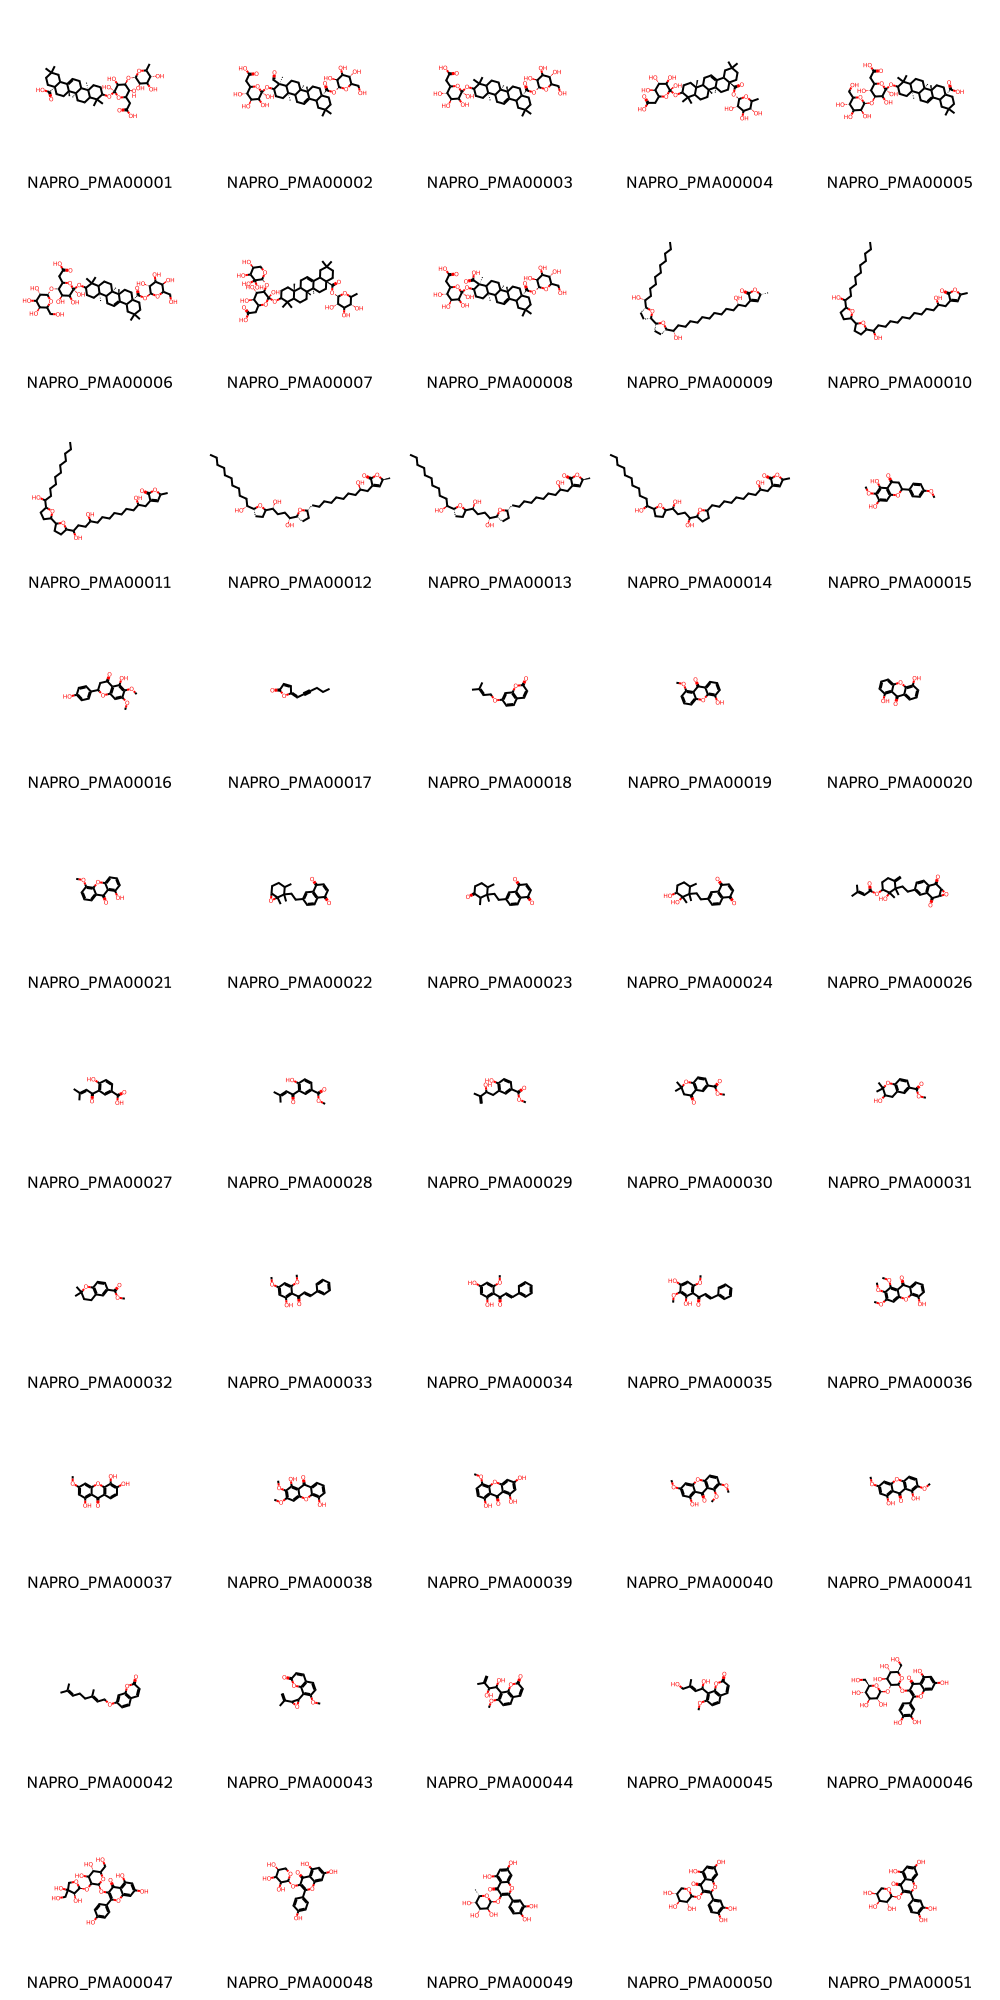

In [64]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import PandasTools, Draw

# Asegurar que la columna SMILES sea de tipo string y no contenga NaNs
xplor['SMILES'] = xplor['SMILES'].fillna('').astype(str)

# Filtrar filas donde SMILES esté vacío para evitar errores
xplor_clean = xplor[xplor['SMILES'] != ''].copy()

# Agregar la columna de moléculas al DataFrame
PandasTools.AddMoleculeColumnToFrame(xplor_clean, smilesCol='SMILES', molCol='ROMol')

# Eliminar filas donde la molécula no pudo ser creada (ROMol es None)
xplor_clean = xplor_clean.dropna(subset=['ROMol'])

# Convertir las leyendas a string para evitar cualquier error de tipo
legends_list = [str(cmpd) for cmpd in xplor_clean['Cmpd'].tolist()]

# Mostrar las moléculas en una cuadrícula
grid_img = Draw.MolsToGridImage(xplor_clean['ROMol'],
                                molsPerRow=5,
                                subImgSize=(200, 200),
                                legends=legends_list)
display(grid_img)

In [65]:
! pip install mordredcommunity

In [66]:
from mordred import Calculator, descriptors

In [67]:
def All_Mordred_descriptors(xplor):
  calc = Calculator(descriptors, ignore_3D=False)
  mols = [Chem.MolFromSmiles(smi) for smi in xplor]

  #pandas df
  df = calc.pandas(mols)
  return df

In [68]:
mordred_descriptors = All_Mordred_descriptors(xplor['SMILES'])
xplor_mordred = pd.concat([xplor, mordred_descriptors], axis=1)

100%|██████████| 515/515 [04:01<00:00,  2.13it/s]


In [69]:
# @title
# Seleccionar solo las características que estaban incluídas en el dataframe incial data
# Esta información adicional será guardada en una variable llamada df_val, con la que trabaja el pipeline
from sklearn.impute import SimpleImputer
import pandas as pd

names = xplor_mordred["Cmpd"]
# Usamos df_x_.columns en lugar de x_train.columns porque x_train es un array de numpy y no tiene el atributo columns
features_to_use = [col for col in df_x_.columns if col in xplor_mordred.columns]
df_val = xplor_mordred[features_to_use].copy() #Esta variable entra al pipeline

# Convertir todos los datos a numéricos, convirtiendo textos como "missing 3D coordinate" en NaN
for col in df_val.columns:
    df_val[col] = pd.to_numeric(df_val[col], errors='coerce')

# Eliminar columnas que estén completamente vacías (todo NaN) antes de imputar
df_val = df_val.dropna(axis=1, how='all')

# Quita las filas que tienen todos los elementos NaN si fuera necesario
df_val = df_val.dropna(how='all')

# Imputar valores faltantes utilizando la media
imputer = SimpleImputer(strategy='mean')
imputed_data = imputer.fit_transform(df_val)

# Reconstruir el DataFrame utilizando las columnas resultantes que sí tienen datos
df_val = pd.DataFrame(imputed_data, columns=df_val.columns, index=df_val.index)
df_val.shape

(515, 1189)

In [70]:
#filtramos los datos por PC
# filtered_dataset1 = df_val.copy()
# filtered_dataset1 = filtered_dataset1[filtered_dataset1['MW'] <= 450]
# filtered_dataset1 = filtered_dataset1[filtered_dataset1['BalabanJ'] <= 2.9]
# # filtered_dataset1 = filtered_dataset1[filtered_dataset1['BalabanJ'] >= 1.4]
# filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA1'] <= 21]
# filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA10'] <= 24]
# # filtered_dataset1 = filtered_dataset1[filtered_dataset1['PEOE_VSA13'] <= 12]
# df_val = filtered_dataset1.copy()
df_val.shape

(515, 1189)

In [71]:
x_train.shape

(427, 1197)

In [72]:
# @title
# Calculamos los valores de predicción y DA para el grupo de exploración, los guardamos en df
# es decir los valores de las nuevas moléculas a predecir o explorar.
import pandas as pd
import numpy as np

# Aseguramos que df_val tenga exactamente las mismas columnas y orden que el df_x_ de entrenamiento
# Rellenamos con 0 las columnas que no existan en df_val pero sí en df_x_
columnas_entrenamiento = list(df_x_.columns)
df_val_alineado = df_val.reindex(columns=columnas_entrenamiento, fill_value=0.0)

# Realizamos la predicción con el conjunto perfectamente alineado
df = pd.DataFrame({"pred": pipeline.predict(df_val_alineado.values)}, index=names)

# Calculamos el dominio de aplicación si APP_DOMAINS está definido
if 'APP_DOMAINS' in globals():
    for model in APP_DOMAINS:
        score = model.decision_function(pipeline[:-1].transform(df_val_alineado.values))
        df[f"{mname(model)}_domain"] = score
else:
    # Si no tienes APP_DOMAINS definido, creamos un leverage simulado para que las siguientes celdas no fallen
    df["LeverageMethod_domain"] = -0.1

df

,pred,LeverageMethod_domain
Cmpd,,
NAPRO_PMA00001,6.144508,-0.1
NAPRO_PMA00002,6.174672,-0.1
NAPRO_PMA00003,6.130753,-0.1
NAPRO_PMA00004,6.136799,-0.1
NAPRO_PMA00005,6.150195,-0.1
...,...,...
Manu027,6.841642,-0.1
Manu028,6.631135,-0.1
Manu029,5.660419,-0.1


In [73]:
# @title
# prompt: a df_v asignale indices
xplor_pred = df.reset_index()
xplor_pred = xplor_pred.drop(columns=['Cmpd'])
#xplor_pred['Cluster_number'] = xplor_mordred['Cluster_number']
# Concatenate xplor and df_v DataFrames
xplor_pred = pd.concat([xplor, xplor_pred], axis=1)

In [74]:
xplor_pred.head()

,Cmpd,SMILES,G,pred,LeverageMethod_domain
0,NAPRO_PMA00001,CC1O[C@@H](O[C@@H]2C(O)[C@](O)(OC3CC[C@@]4(C)C...,xplor,6.144508,-0.1
1,NAPRO_PMA00002,CC1(C)CC[C@]2(C(=O)O[C@H]3OC(CO)[C@@H](O)C(O)[...,xplor,6.174672,-0.1
2,NAPRO_PMA00003,CC1(C)CC[C@]2(C(=O)O[C@H]3OC(CO)[C@@H](O)C(O)[...,xplor,6.130753,-0.1
3,NAPRO_PMA00004,CC1O[C@@H](OC(=O)[C@]23CCC(C)(C)CC2C2=CCC4[C@@...,xplor,6.136799,-0.1
4,NAPRO_PMA00005,CC1(C)CC[C@]2(C(=O)O)CC[C@]3(C)C(=CCC4[C@@]5(C...,xplor,6.150195,-0.1


# PREDICCIONES

In [75]:
#definimos el umbral
da_limit = 0  #Eje x
activity_limit =0 #Eje y

In [76]:
# Creamos uan gráfica de valores predichos respecto al Dominio de Aplicación
fig = px.scatter(xplor_pred, x="LeverageMethod_domain", y="pred",
                 title="LeverageMethod_domain vs pred",
                 width= 900,height = 500)

#___________Respecto a la linea_________________________________________________
fig.add_vline(x=0, line_width=3, line_color="green")
fig.add_hline(y=activity_limit, line_width=3, line_color="green")

fig.update_layout(plot_bgcolor="white",  # Establecer color de fondo
                  paper_bgcolor="white")   # Establecer el color de fondo del papel
#___________Respecto al formato_________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=xplor_pred,
                                     smiles_col='SMILES',
                                    # title_col='Cmpd',
                                     #color_col='fraction',
                                     caption_cols=['Cmpd'],
                                     fontsize=15,
                                     width=220)
app_marker.run(port=8705)
#fig.show()

<IPython.core.display.Javascript object>

### filtracion

In [77]:
# Vamos a utiliza un umbral para filtrar los valores con leverage mayor que 0 y con valor predicted mayor a 5.2
filtered = xplor_pred[(xplor_pred['LeverageMethod_domain'] < da_limit) & (xplor_pred['pred'] >activity_limit)]
filtered.shape

(515, 5)

In [78]:

#____________________________________________________________________________
# Graficamos la información filtrada
fig = px.scatter(filtered, x="LeverageMethod_domain", y="pred",
                 title="LeverageMethod_domain vs pred",
                 width= 900,height = 500)
#___________Respecto a la linea_________________________________________________
fig.add_vline(x=0, line_width=3, line_color="green")
fig.add_hline(y=activity_limit, line_width=3, line_color="green")
fig.update_layout(plot_bgcolor="white",  # Set plot background color
    paper_bgcolor="white")   # Set paper background color
#_____________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                      df=filtered,
                                      smiles_col='SMILES',
                                    caption_cols=['Cmpd', 'G'],
                                      fontsize=15, width=220)

app_marker.run(port=8706)

<IPython.core.display.Javascript object>

In [79]:
save=False
if save is True:
  XPLOR = filtered[['pred',	'Cmpd',	'SMILES',	'G']]
  XPLOR = filtered.rename(columns={'pred': 'Activity'})
  XPLOR.to_excel('XPLOR_1.xlsx', index=False)
  print('SE guardó XPLOR')
else:
  print('No se guardó XPLOR')

No se guardó XPLOR


# ESPACIO QUÍMICO



El espacio químico es un concepto fundamental en quimioinformática, es asociado con el conjunto de todas las moléculas posibles, que están descritas por un espacio multidimensional que representa propiedades estructurales, así como funcionales y su relación entre las moléculas molecular.

Se hace uso de dos tipos de representaciones

1.- Por PCA (Análisis de componentes principales)


2.- Por T-SNE,  (t-Distributed Stochastic Neighbor Embedding, por sus siglas en inglés) o Incrustación de vecinos estocásticos distribuidos en t.

Los descriptores que se representan en el espacio químico son

### Espacio químico descriptores

In [80]:
df_info = data[['Molecule ChEMBL ID', 'SMILES', 'Cluster_number']].copy()
df_info = df_info.rename(columns={'Molecule ChEMBL ID': 'Cmpd'})

In [81]:
DATA_xplor = filtered.copy()
DATA_data = df_info.copy()
# combinas DATA_data con df_y_
# Convert df_y_ to a Pandas Series before concatenation
DATA_data = pd.concat([DATA_data, pd.Series(df_y_, name='Activity')], axis=1)

In [82]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import numpy as np
import pandas as pd

# Generar descriptores
# Asegurarse de que la columna 'SMILES' contenga solo cadenas. Convertir tipos no-string a cadenas vacías, que Chem.MolFromSmiles puede manejar (devuelve None).
DATA_data['SMILES'] = DATA_data['SMILES'].apply(lambda x: str(x) if pd.notna(x) else '')

# Crear una lista de objetos de molécula RDKit. Las SMILES inválidas resultarán en None.
mols = [Chem.MolFromSmiles(x) for x in DATA_data["SMILES"]]

# Calcular descriptores, manejando los casos en que Chem.MolFromSmiles haya devuelto None
DATA_data["HBA"] = [Descriptors.NumHAcceptors(m) if m is not None else np.nan for m in mols]
DATA_data["HBD"] = [Descriptors.NumHDonors(m) if m is not None else np.nan for m in mols]
DATA_data["RB"] = [Descriptors.NumRotatableBonds(m) if m is not None else np.nan for m in mols]
DATA_data["LogP"] = [Descriptors.MolLogP(m) if m is not None else np.nan for m in mols]
DATA_data["TPSA"] = [Descriptors.TPSA(m) if m is not None else np.nan for m in mols]
DATA_data["MW"] = [Descriptors.MolWt(m) if m is not None else np.nan for m in mols]


In [83]:
# Generar descriptores
DATA_xplor["HBA"] = [Descriptors.NumHAcceptors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["HBD"] = [Descriptors.NumHDonors(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["RB"] = [Descriptors.NumRotatableBonds(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
#DATA_xplor["RB"] = [Descriptors.MinPartialCharge(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["LogP"] = [Descriptors.MolLogP(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["TPSA"] = [Descriptors.TPSA(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]
DATA_xplor["MW"] = [Descriptors.MolWt(y) for y in (Chem.MolFromSmiles(x) for x in DATA_xplor["SMILES"])]

In [84]:
chemspace_data = DATA_data.copy()
#A chemspace_data agrega una columna llada G , que tenga el valor 'data' para todos los elementos
chemspace_data['G'] = 'data'
# Fusionar chemspace_data con xplor_pred según la columna 'Cmpd'
chemspace_data = pd.merge(chemspace_data, xplor_pred[['Cmpd', 'LeverageMethod_domain']], on='Cmpd', how='left')
# Now chemspace_data contains the 'LeverageMethod_domain' column from xplor_pred.
#chemspace_data

In [85]:
chemspace_xplor = DATA_xplor.copy()
# prompt: en chemspace_xplor elimina las columnas: ZIN_ID, G, Component1, Component2, Component3
chemspace_xplor = chemspace_xplor.drop(columns=['ZINC_ID', 'component1', 'component2', 'component3'], errors='ignore')
# prompt: en chemspace_xplor cambia el nombre de la columna 'pred' por 'Activity'
chemspace_xplor = chemspace_xplor.rename(columns={'pred': 'Activity'})
# prompt: agrega la columna G a chemspace_xplor

#chemspace_xplor['G'] = 'comb'
#chemspace_xplor['Cluster_number'] = int(len(set(cluster_id))+1)

In [86]:
# Concatenar a lo largo de filas (eje=0)
chemspace = pd.concat([chemspace_data, chemspace_xplor], axis=0, ignore_index=True)

# Si es necesario, puede restablecer el índice:
# chemspace = chemspace.reset_index()

# A chemspace, agrega, una columna que se llame G2, que tenga valores numéricos para cada valor de G, esto servira mása adelante para visualizar datos en molplotly
# Crear un mapeo de valores 'G' a valores numéricos
g_mapping = {'data': 1, 'xplor': 2, 'comb': 3}  # Example mapping
# Cree la columna 'G2' en función del mapeo
chemspace['G2'] = chemspace['G'].map(g_mapping)
# Añadimos una columna que nos permitirá visualizar la información de los clusters con plotly

chemspace['cn_s'] = 'Cluster ' + chemspace['Cluster_number'].astype(str)
# Crear una asignación de valores de Cluster_number a valores numéricos
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(chemspace['Cluster_number'].unique()))}
# Crea la columna 'cn' en función del mapeo
chemspace['cn'] = chemspace['Cluster_number'].map(cluster_mapping)

In [87]:
chemspace

,Cmpd,SMILES,Cluster_number,Activity,HBA,HBD,RB,LogP,TPSA,MW,G,LeverageMethod_domain,G2,cn_s,cn
0,CHEMBL195241,Cc1c(N2CCN(C)CC2)nc2ccccc2c1C(=O)NCCCCCCCNc1c2...,1.0,8.390000,6,2,11,6.51442,73.39,578.805,data,NaN,1,Cluster 1.0,1
1,CHEMBL3883432,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCCCNc4c5c(...,1.0,8.890000,6,1,13,7.88000,70.47,649.905,data,NaN,1,Cluster 1.0,1
2,CHEMBL3884858,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCNc4c5c(nc6...,1.0,7.740000,6,1,10,6.70970,70.47,607.824,data,NaN,1,Cluster 1.0,1
3,CHEMBL3885186,O=S(=O)(c1ccccc1)n1ccc2c(N3CCN(CCCCCCNc4c5c(nc...,1.0,7.890000,6,1,11,7.09980,70.47,621.851,data,NaN,1,Cluster 1.0,1
4,CHEMBL2064469,CCN(CCCN1CCN(CCNc2c3c(nc4ccccc24)CCCC3)CC1)C1C...,1.0,6.710000,5,1,10,5.18780,34.64,477.741,data,NaN,1,Cluster 1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1120,Manu027,O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5...,NaN,6.841642,6,0,2,4.00930,49.58,393.443,xplor,-0.1,2,Cluster nan,53
1121,Manu028,O=C(O1)C=CC2=C1C=CC3=C2SC(N(C[C@@H]4C5)[C@@H]5...,NaN,6.631135,6,0,2,4.88900,49.58,443.450,xplor,-0.1,2,Cluster nan,53
1122,Manu029,CCN1C=C(C(O)=O)C(C2=CC(F)=C(N3[C@@H]4CN(C5N(C6...,NaN,5.660419,9,2,6,3.75330,128.08,622.704,xplor,-0.1,2,Cluster nan,53
1123,Manu030,O=C(C1=CC(F)=C(N2[C@@H]3CN(C4N(C5=NC(C=CC(OC)=...,NaN,5.640662,9,1,6,4.11850,108.21,607.689,xplor,-0.1,2,Cluster nan,53


### Representación de propiedades

In [88]:
# @title
# prompt: has una matriz de dispersión con plotly, con el df chemspace

import plotly.express as px
#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#________________Definimos la gráfica______________________________
fig1 = px.scatter_matrix(data_frame=a,
                         #data_frame=a, #Por si se enciman los datos
                         #_________________________________
                         dimensions=["HBA", "HBD", "RB", "LogP", "TPSA", "MW", 'Activity'
                                     ],
                         #_______color_________________________________________
                         color="G",#color="cn_s",
                        #  color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'}, # <-- Add this line to define colors for G2 values
                         #color_discrete_sequence=px.colors.qualitative.Dark24,
                         #____________Color___________________________________
                         title='Matriz de dispersión del Espacio Químico, Descriptores Individuales ',
                         height=1000,width=1500)
#________________Formato________________________________________________________
# fig1.update_layout(plot_bgcolor="white", paper_bgcolor="white")  # Set plot background color
fig1.update_traces(diagonal_visible=False, #marker=dict(line=dict(width=1, color='black'))
) #Added marker settings
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig1,
                                     #_________________________________________
                                     df=a,
                                     #df=a,
                                     #_________________________________________
                                     smiles_col='SMILES',
                                     #____color_______________________________
                                     color_col='G', #color="cn_s",
                                     caption_cols=['Cmpd', 'G', 'cn_s',"HBA", "HBD", "RB", "LogP", "TPSA", "MW", 'Activity'],
                                     show_coords=False,
                                     #________________________________________
                                     fontsize=20, width=350)
app_marker.run(port=8960)
#fig.show()

<IPython.core.display.Javascript object>

In [89]:
import plotly.express as px
import molplotly

# Creamos una gráfica donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# lás moléculas de los datos iniciales

#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#________________Definimos la gráfica______________________________

fig = px.scatter(data_frame=a, x="LogP", y="Activity",
                 title="Características individuales",
                #  size='Activity', # Set bubble size based on Activity


                 #_______Color_________________________
                 color = 'cn_s',
                 height= 700, width= 1500,



                 )
#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color
fig.update_traces(marker=dict(line=dict(width=1, color='black')))
fig.update_traces(marker=dict(size=12)) # Base size, will be scaled by 'Activity'
##_________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=a,
                                     smiles_col='SMILES',
                                     color_col = 'cn_s',
                                     caption_cols=['Cmpd', 'Activity', 'G'],
                                     fontsize=20, width=350)
app_marker.run(port=8961)

<IPython.core.display.Javascript object>

In [90]:
# Creamos una gráfica de dispersión en 3D donde se puden ver las propiedades individuales de las moléculas a evaluar comparadas con
# lás moléculas de los datos iniciales

#________________Por si se enciman los datos_________________________________
a = chemspace.copy()
#a = chemspace[chemspace['cn'].isin([2,3,4,5,6,7,8,9,10,11,12,13])]
#a = chemspace[chemspace['G2'].isin([0,1,3])]
#___________________________________________________________________________
#________________Definimos la gráfica______________________________
fig = px.scatter_3d(data_frame=a, x="MW", y="LogP", z="Activity",
                    title="Características individuales",
                    #_____color________
                    color='G',
                    #color = 'cn'
                    )
#________________Formato________________________________________________________
fig.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Set background color
#_______________________________________________________________________________
app_marker = molplotly.add_molecules(fig=fig,
                                     df=a,
                                     smiles_col='SMILES',
                                     color_col='G',
                                     fontsize=15,
                                     show_coords=False,
                                     caption_cols=['Cmpd','Activity', 'G'],
                                     width=210)
app_marker.run(port=8707)

<IPython.core.display.Javascript object>

# Representación del Espacio Químico por PCA





## Preparación

Se usa para reducir la dimensionalidad, asignando pesos a los descriptores, y generando los nuevos Componentents Principales. Esto nos permite visualizar la represeantación del espacio Químico en dos o tres dimensiones.

Las moléculas que comparten propiedades se acercan entre si, y entre más distintas sean entre ellas, mayor será la distancia euclidiana entre los puntos.

In [91]:
data_k=chemspace.copy()
#Dividir matriz
data_k = data_k.iloc[:,4:10].values # Seleccionar columnas con descriptores
data_k = pd.DataFrame(data_k)
#data

In [92]:
# Normalizar datos
from sklearn.preprocessing import StandardScaler
data_std = StandardScaler().fit_transform(data_k)

In [93]:
# pca.fit
from sklearn.decomposition import PCA
pca = PCA(n_components=3)
pca_results = pca.fit_transform(data_std)
#pca_results

In [94]:
# Seleccionar información complementaria
label = chemspace[["Cmpd", "SMILES", "Activity", 'G', 'Cluster_number']]
label = label.to_numpy()

In [95]:
# Concatenar matrices de numpy
arr = np.concatenate((label, pca_results), axis = 1)
# Crear un nuevo dataframe
pca_dataset = pd.DataFrame(data=arr, columns = ['Cmpd',"SMILES", "Activity",'G','Cluster_number','component1', 'component2', 'component3'])
#pca_dataset.head(2)

In [96]:
#Las cargas (loadings) representan los pesos o coeficientes de los PC's
loadings = []
#Inicia un bucle que itera sobre cada componente principal.
# pca.n_components se refiere al número de componentes principales calculados durante el análisis PCA.
# # pca.components_ es un atributo del objeto PCA ajustado (fit) que almacena las cargas (loadings) de todos los componentes principales.
for i in range(pca.n_components):
  loadings.append(pca.components_[i])
#pca loadings es una datafrme que relaciona los descripotres con los pesos de los PCA´s
pca_loadings = pd.DataFrame(data=loadings, columns=data_k.columns)
# Renombramos las columnas
pca_loadings = pca_loadings.rename(columns={0: "HBA", 1: "HBD", 2: "RB", 3: "LogP", 4: "TPSA", 5: "MW"})
# A pca_loadings vuelve cambia el indice qu ecomience desde uno
pca_loadings.index = range(1, len(pca_loadings) + 1)

In [97]:
# Obtenemos las ecuaciones de PC's
equations = {}
for index, row in pca_loadings.iterrows():
  equation = "PC{} = ".format(index)
  for col, value in row.items():
    equation += "{:.4f}*{} + ".format(value, col)
  equations["PC{}".format(index)] = equation[:-3]  # Remove the last " + "
for pc, equation in equations.items():
  print(equation)

PC1 = 0.5150*HBA + 0.4808*HBD + 0.1036*RB + -0.2940*LogP + 0.5231*TPSA + 0.3645*MW
PC2 = -0.0025*HBA + -0.1136*HBD + 0.6695*RB + 0.5426*LogP + -0.0626*TPSA + 0.4905*MW
PC3 = 0.0446*HBA + -0.2180*HBD + 0.6772*RB + -0.6225*LogP + -0.1179*TPSA + -0.3009*MW


###  PCA representación de pesos



Muestra la relación de los descriptres con respecto a los primeros 3 componentes principales.

In [98]:
import plotly.graph_objects as go

In [99]:
# @title
# Crea una figura
figx = go.Figure()
# Itera sobre cada índice (PC) y agrega trazas (inforación de cada PC) al gráfico de barras
for index in pca_loadings.index:
  figx.add_trace(go.Bar(x=pca_loadings.columns, # Nombres de los descriptores
                        y=pca_loadings.loc[index],  # Valores para cada uno de los PC's
                        name=index))  # Nombre de la traza (PC)
#____________Formateo_______________
figx.update_layout(title="Contribución de los Descriptores a cada PC para el Espacio Químico",
                   xaxis_title="Descriptores",
                   yaxis_title="Weight",
                   plot_bgcolor='white',
                   paper_bgcolor='white',
                   barmode='group')  # Agrupa las barras por descriptor
figx.show()# Muestra la figura

### PCA varianza acumulada

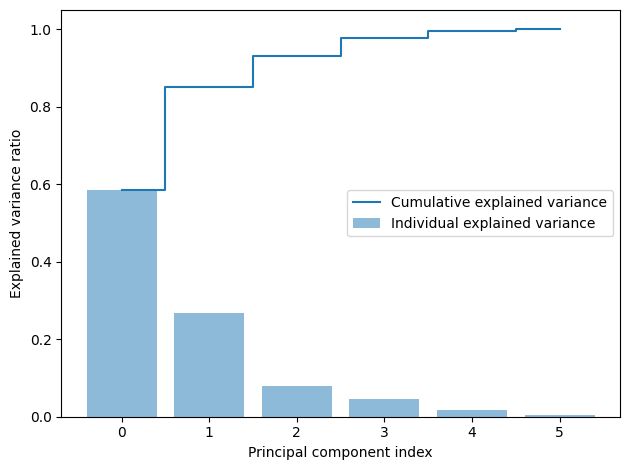

In [100]:
# @title
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(data_k)
X_train_std = sc.transform(data_k)

pca = PCA()

# Determine transformed features
X_train_pca = pca.fit_transform(X_train_std)

# Determine explained variance using explained_variance_ration_ attribute
exp_var_pca = pca.explained_variance_ratio_
#
# Cumulative sum of eigenvalues; This will be used to create step plot
# for visualizing the variance explained by each principal component.
cum_sum_eigenvalues = np.cumsum(exp_var_pca)
#
# Create the visualization plot
import matplotlib.pyplot as plt
plt.bar(range(0,len(exp_var_pca)), exp_var_pca, alpha=0.5, align='center', label='Individual explained variance')
plt.step(range(0,len(cum_sum_eigenvalues)), cum_sum_eigenvalues, where='mid',label='Cumulative explained variance')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

In [101]:
# Agregue la columna 'Levarage_domain' a pca_dataset
da = chemspace['LeverageMethod_domain']  # Using chemspace DataFrame to access the column
# Restablecer el índice de pca_dataset para que coincida con chemspace
pca_dataset = pca_dataset.reset_index(drop=True)
# Agregar la nueva columna a pca_dataset
pca_dataset['LeverageMethod_domain'] = da

## Representación del espacio químico por PCA



### Preparación

In [102]:
# Crea una columna en pca_dataset que se llamará cn, tendra valores numéricos uno para cada tipo de valor de Cluster_number
# Crear una asignación de valores de Cluster_number a valores numéricos
cluster_mapping = {cluster: i + 1 for i, cluster in enumerate(sorted(pca_dataset['Cluster_number'].unique()))}
# Crea la columna 'cn' en función del mapeo
pca_dataset['cn'] = pca_dataset['Cluster_number'].map(cluster_mapping)
# Crea una columna en pca_datset, se llamará cn_s, tendra valores en cadenas dirán cluster + n, donde es el número de cluster
pca_dataset['cn_s'] = 'cluster ' + pca_dataset['cn'].astype(str)
# Cree la columna 'G2' en función de la asignación
pca_dataset['fraction1'] = pca_dataset['G'].map(g_mapping)

In [103]:
# @title
#Graficar gráfica de dispersión Activity vs PC1

#________________Por si se enciman los datos_________________________________
a = pca_dataset.copy()
# a = pca_dataset[pca_dataset['G'] != 'xplor'].copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]# Filter out 'xplor' group
#a = pca_dataset[pca_dataset['cn'].isin([1,2,3,4,5,6,.7,8,9,10,11,12,13])]
#________________Definimos la gráfica_______________________________________

dato1='component1'
dato3='Activity'
#________________
dato2='component2'
#___________________________________________________________________________
fig_pca = px.scatter(data_frame=a, #Por si se enciman los datos
                     #____coordenadas______________--
                     x=dato1,y=dato3,
                     #_____Color_____________-color='cn',
                     color='G',
                     color_discrete_map={'data': 'blue', 'comercial': 'red'}, # Invierte colores
                     #______________________
                     title=f'{dato2} vs {dato1}',
                     width=800,height=600)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") # Elige color del fondo
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) # Configuración de marcador agregada
fig_pca.update_traces(marker=dict(size=12)) # Aumentar el tamaño del marcador
#______________________________________________________________________________

# Añadir anotaciones SÓLO para puntos 'comerciales'
for index, row in a.iterrows():
    if row['G'] == 'comercial': # Solo agregue etiquetas para el grupo 'comercial'
        fig_pca.add_annotation(
            x=row[dato1],
            y=row[dato2],
            text=row['Cmpd'],
            showarrow=False,
            yshift=10,  # Desplazar el texto ligeramente por encima del punto
            font=dict(
                size=14,
                color="black"
            )
        )

app_marker2dpca = molplotly.add_molecules(fig=fig_pca,
                                     #_____________dataframe___________________
                                     df=a,
                                     #__________________________________________
                                     smiles_col='SMILES',
#                                    title_col='Cmpd',
                                     #_____________color_________________________
                                     color_col='G',
                                     #color_col='cn',
                                     #_________________________________________
                                    fontsize=20, width=220,
                                     caption_cols=[dato3, 'Cmpd'],
                                     show_coords=False)


In [104]:
# @title
#Grafica de dispersión en 3D Activity vs PC1 vs PC2
#________________Por si se enciman los datos_________________________________

a = pca_dataset.copy()
#a = pca_dataset[pca_dataset['fraction1'].isin([])]
#a = pca_dataset[pca_dataset['cn'].isin([6,9,#10,11,12,13])]

#________________Definimos la gráfica_______________________________________
dato1='component1'
#dato2='Activity'
dato2='component3'
dato3='component2'
#_________
dato4='Activity'
#dato4='component3'
#__________________________________________________________________________
fig_pca = px.scatter_3d(data_frame=a,
                        #data_frame=a, #Por si se enciman los datos
                        #______coordenadas__________________________________
                        x=dato3,
                        y=dato1,
                        z=dato2,
                        #______color________________________________________
                        color='G',
                        #color='cn',
                        #___________________________________________________
                        title=f'{dato2} vs {dato1} vs {dato3}',
                        width=900, height=900)
#______________formateo_______________________________________________________
fig_pca.update_layout(plot_bgcolor="white", paper_bgcolor="white") #Set background color
fig_pca.update_traces(marker=dict(line=dict(width=1, color='black'))) #Added marker settings
fig_pca.update_traces(marker=dict(size=5)) # Increase marker size
#______________________________________________________________________________
app_marker3dpca = molplotly.add_molecules(fig=fig_pca,
                                     #___________dataframe__________________
                                     df=a,
                                     #df=a,
                                     #______________________________________
                                     smiles_col='SMILES',
                                   #  title_col='cn_s',
                                     #____________color_____________________
                                     #color_col='cn',
                                     color_col='G',
                                     #________________________________________
                                     show_coords=False,
                                     caption_cols=[dato4,'Cmpd','G'],
                                     fontsize=15, width=210)


## Gráficas

In [105]:
figx.update_layout(width=800, height=250)
figx.show()
app_marker2dpca.run(port=8708)
app_marker3dpca.run(port=8709)



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# UMAP



In [106]:
! pip install umap-learn
import umap

In [107]:
# Select the descriptor columns from chemspace for UMAP
descriptor_cols = ['HBA', 'HBD', 'RB', 'LogP', 'TPSA', 'MW']
X_descriptors = chemspace[descriptor_cols].copy()

# Handle potential NaN values by imputing with the mean (similar to previous steps for other models)
imputer = SimpleImputer(strategy='mean')
X_imputed = imputer.fit_transform(X_descriptors)

# Apply StandardScaler to the descriptors
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Apply UMAP dimensionality reduction (using 3 components for more detail, can be changed to 2)
reducer = umap.UMAP(n_components=3, random_state=RANDOM_STATE)
umap_results = reducer.fit_transform(X_scaled)

# Create a DataFrame for UMAP results
umap_df = pd.DataFrame(umap_results, columns=['UMAP1', 'UMAP2', 'UMAP3'])

# Add relevant original columns to the UMAP DataFrame
umap_df['Cmpd'] = chemspace['Cmpd'].values
umap_df['SMILES'] = chemspace['SMILES'].values
umap_df['Activity'] = chemspace['Activity'].values
umap_df['Cluster_number'] = chemspace['Cluster_number'].values
umap_df['G'] = chemspace['G'].values



In [108]:
import plotly.express as px
import warnings

warnings.filterwarnings("ignore", message="JupyterDash is deprecated, use Dash instead.")

# Prepare data for plotting, ensuring 'G' is properly handled for color
umap_df['G_category'] = umap_df['G'].astype('category')

# 2D UMAP Scatter Plot
fig_umap2d = px.scatter(umap_df,
                        x='UMAP1', y='UMAP2',
                        color='G_category',
                        color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'},
                        title='2D UMAP Visualization of Chemical Space',
                        width=900, height=700)

fig_umap2d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap2d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap2d.update_traces(marker=dict(size=12))
fig_umap2d.update_layout(hoverlabel_font_size=20)

app_umap2d = molplotly.add_molecules(
    fig=fig_umap2d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=220
)

print('2D UMAP plot created. Running on port 8717.')
app_umap2d.run(port=8717)

# 3D UMAP Scatter Plot
fig_umap3d = px.scatter_3d(umap_df,
                         x='UMAP1', y='UMAP2', z='UMAP3',
                         color='G_category',
                         color_discrete_map={'data': 'blue', 'xplor': 'red', 'comercial': 'green'},
                         title='3D UMAP Visualization of Chemical Space',
                         width=900, height=900)

fig_umap3d.update_layout(plot_bgcolor='white', paper_bgcolor='white')
fig_umap3d.update_traces(marker=dict(line=dict(width=1, color='black')))
fig_umap3d.update_traces(marker=dict(size=8))
fig_umap3d.update_layout(hoverlabel_font_size=20)

app_umap3d = molplotly.add_molecules(
    fig=fig_umap3d,
    df=umap_df,
    smiles_col='SMILES',
    color_col='G_category',
    caption_cols=['Cmpd', 'Activity', 'Cluster_number', 'G'],
    fontsize=15, width=210
)

print('3D UMAP plot created. Running on port 8718.')
app_umap3d.run(port=8718)

2D UMAP plot created. Running on port 8717.


<IPython.core.display.Javascript object>

3D UMAP plot created. Running on port 8718.


<IPython.core.display.Javascript object>

In [109]:
app_umap2d.run(port=8717)
app_umap3d.run(port=8718)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>